<div style="border: 4px solid #4472C4; border-radius: 8px; padding: 16px 20px; background-color: #blue;">
    
# Explainable Artificial Intelligence (XAI) for PhysNet Transfer Learning


<h2>Overview</h2>

<p>
This Jupyter notebook provides a unified framework for analyzing the evolution of a PhysNet machine-learning potential during transfer learning from Hartree–Fock (HF)/Møller–Plesset perturbation theory of second order (MP2) to coupled-cluster [CCSD(T)] reference data for malonaldehyde.</p>
</div>


<div style="border: 4px solid #4472C4; border-radius: 8px; padding: 16px 20px; background-color: #red;">

The primary objective is to investigate how the neural-network (NN) representation and predicted physical properties evolve as a function of the number of transfer-learning steps, $N$. Particular attention is given to the relationship between changes in atomic feature representations $\mathbf{\mathcal{F}^{\alpha}_k}$ and the underlying structural transformations in the Euclidean space.

**Molecular Dynamics (MD):** We examine changes in atomic feature representations along finite-temperature MD trajectories, focusing on structural fluctuations and intramolecular hydrogen-transfer events. The evolution of feature-vector cosine similarity and magnitude is analyzed in relation to atomic energy contributions and molecular geometry.

**Normal Modes (NM):** We investigate the response of atomic feature representations to systematic displacements along selected vibrational normal modes. This allows us to characterize changes in feature-vector directions and magnitudes as functions of the displacement coordinate.

**Minimum-Energy Path (MEP):** We analyze the evolution of atomic feature representations along the reaction pathway connecting the reactant state (RS), transition state (TS), and product state (PS). Changes in feature cosine similarity, magnitude, and individual feature components are examined alongside variations in molecular geometry, atomic energies, and Wiberg bond indices.
</div>

<div style="border: 4px solid #4472C4; border-radius: 8px; padding: 16px 20px; background-color: #red;">

## Python Analysis Framework

The notebook uses standalone Python classes located in the `~/XAI/` directory. Each class is responsible for extracting, processing, and visualizing a particular aspect of the PhysNet model.

| Python class | Description |
|---|---|
| `XAIDataPipeline` — `xai_data_pipeline.py` | Extracts energy barriers and test-set prediction errors across transfer-learning checkpoints. |
| `BarrierMAEScatter` — `xai_barrier_scatter.py` | Examines the relationship between energy-barrier predictions and energy mean absolute errors (MAE). |
| `FeatureSimilarity` — `xai_feature_similarity.py` | Analyzes atomic feature-vector similarity between transfer-learning checkpoints. |
| `MEPAnalysis` — `xai_mep.py` | Investigates molecular structural changes, atomic feature magnitudes, energies, and bond-order evolution along the MEP. |
| `NormalModesAnalysis` — `xai_normal_modes.py` | Characterizes feature similarity and feature magnitudes under normal-mode displacements. |
| `XAISpearman` — `xai_spearman.py` | Computes cosine similarity and Spearman rank correlation of molecular kernel representation matrices (KRMs), including comparisons between models with and without electrostatics, and their relationship to energy MAE and electrostatic energy. |
| `MDFeatureEnergy` — `xai_md_feature_energy.py` | Investigates correlations between atomic feature-vector magnitudes and module-resolved atomic energy contributions along MD trajectories. |
</div>

<div style="border: 4px solid #4472C4; border-radius: 8px; padding: 16px 20px; background-color: #red;">
    
## Organization of the Notebook

Each analysis section contains:

1. **Scientific background:** The physical question and mathematical quantities being investigated.
2. **Data extraction:** Loading and processing reference calculations, neural-network predictions, and intermediate representations.
3. **Visualization:** Generating publication-quality figures with adjustable plotting parameters.
4. **Output:** Saving processed numerical data and figures for subsequent analysis.

The classes are designed to separate computationally intensive data extraction from visualization. Processed quantities are stored in `~/XAI/data/`, allowing figures to be reproduced or modified without repeatedly loading large trajectory or neural-network activation files.
</div>

<div style="border: 4px solid #4472C4; border-radius: 8px; padding: 16px 20px; background-color: #red;">

## Data and Reproducibility

The Python classes and Jupyter notebooks are maintained in the [XAI GitHub repository](https://github.com/chaton1999/xai).

Large simulation datasets, reference energies, trajectories, and pretrained neural-network checkpoints are stored separately in `~/XAI/project_feature/` . These can also be regenerated using scripts placed in XAI/examples. Subsequent users may use **{Tensorflow/PyTorch/Jax}**, the logic shall remain the same. 

All reported numerical results depend on the corresponding reference datasets, model checkpoints, and simulation configurations. The analysis scripts provide the processing and visualization procedures but do not replace the underlying scientific data.

---

**Analysis system:** Malonaldehyde  
**Machine-learning architecture:** PhysNet  
**Transfer-learning protocol:** HF/mp2 → CCSD(T)  
**Reference checkpoint:** ($N = 10^{6}$), unless otherwise specified  
**Primary analysis:** Feature representations, energy prediction errors, electrostatics, normal modes, molecular dynamics, and minimum-energy reaction paths

<div style="border: 4px solid navy; border-radius: 8px; padding: 16px 20px; background-color: lightblue; color: black;">

## Cell 1
---
### Evaluation of Barrier height ($E_{\rm b}$), MAE($E_{\rm i}$), MAE($F_{\rm i}$) and MAE($\mu$)  

PhysNet by construction is predicts energy $E_{\rm i}$, forces $F_{\rm i}$, charges $q_{\rm i}$ and dipoles $\mu$. TL, by and large, adjusts these quantities for a larger dataset at the lower level (HF), which contains larger samples of Euclidean geometry. While tracing the  MAE($E_{\rm i}$), MAE($F_{\rm i}$) and MAE($\mu$) along TL steps $N$ illustrates the quantitative convergence, $E_{\rm b}$ picks up the event when the model learns about the conformational energy.

---

### Computational Implementation

The analysis is implemented using the `XAIDataPipeline` class defined in `xai_data_pipeline.py`. The class provides a common interface for extracting, organizing, and visualizing the evolution of the energy barrier ($E_{\rm b}$) and prediction errors during transfer learning.

The computational workflow consists of three stages:

1. **Data extraction:** The class reads the energy predictions along the minimum-energy path and the test-set prediction errors for the available transfer-learning checkpoints, $N$. The energy barrier is obtained from the energy difference between the transition state (TS) and reactant state (RS), while the mean absolute errors (MAEs) are extracted for energy, forces, and dipole moments.

2. **Data organization:** The extracted quantities are associated with their corresponding checkpoint numbers and saved as numerical data files in `~/XAI/data/`. This separates the processing of the original reference data from subsequent plotting operations.

3. **Visualization:** The Jupyter cell uses the processed data to generate a multi-panel figure showing $E_{\rm b}$, MAE($E_{\rm i}$), MAE($F_{\rm i}$), and MAE($\mu$) as functions of the transfer-learning steps, $N$. The checkpoint axis is displayed on a logarithmic scale to resolve changes across the different stages of transfer learning.

Plotting parameters, including axis limits, figure dimensions, font sizes, line styles, and output settings, are controlled directly from the Jupyter cell. Once the data have been extracted, the figures can be regenerated without repeating the original data-processing procedure.

---

**Implementation:** `~/XAI/xai_data_pipeline.py`  
**Processed data:** `~/XAI/data/`  
**Reference checkpoint:** $N=10^6$

---
</div>



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


,checkpoint,Eb_true,EMAE_true,FMAE_true,DMAE_true,Eb_false,EMAE_false,FMAE_false,DMAE_false
0,1,9.931830,282.732365,10.495961,0.043778,9.872108,282.693283,10.558071,0.041454
1,2,9.773794,281.907015,9.891008,0.042082,9.725074,282.371502,10.008244,0.038171
2,3,9.591610,281.011820,9.307105,0.040364,9.546032,282.039314,9.462766,0.034690
3,4,9.384136,279.989502,8.711902,0.038633,9.360580,281.682036,8.913139,0.031257
4,5,9.154756,278.945056,8.075047,0.036485,9.160461,281.300351,8.327055,0.027744
...,...,...,...,...,...,...,...,...,...
1994,996000,3.876793,0.072334,0.038558,0.000365,3.905711,0.009830,0.058245,0.000357
1995,997000,3.876177,0.019068,0.052790,0.000329,3.876608,0.077700,0.054024,0.000503
1996,998000,3.872835,0.016250,0.042860,0.000616,3.899484,0.013152,0.049102,0.000322
1997,999000,3.850051,0.172892,0.091061,0.000282,3.890076,0.087099,0.054973,0.000287


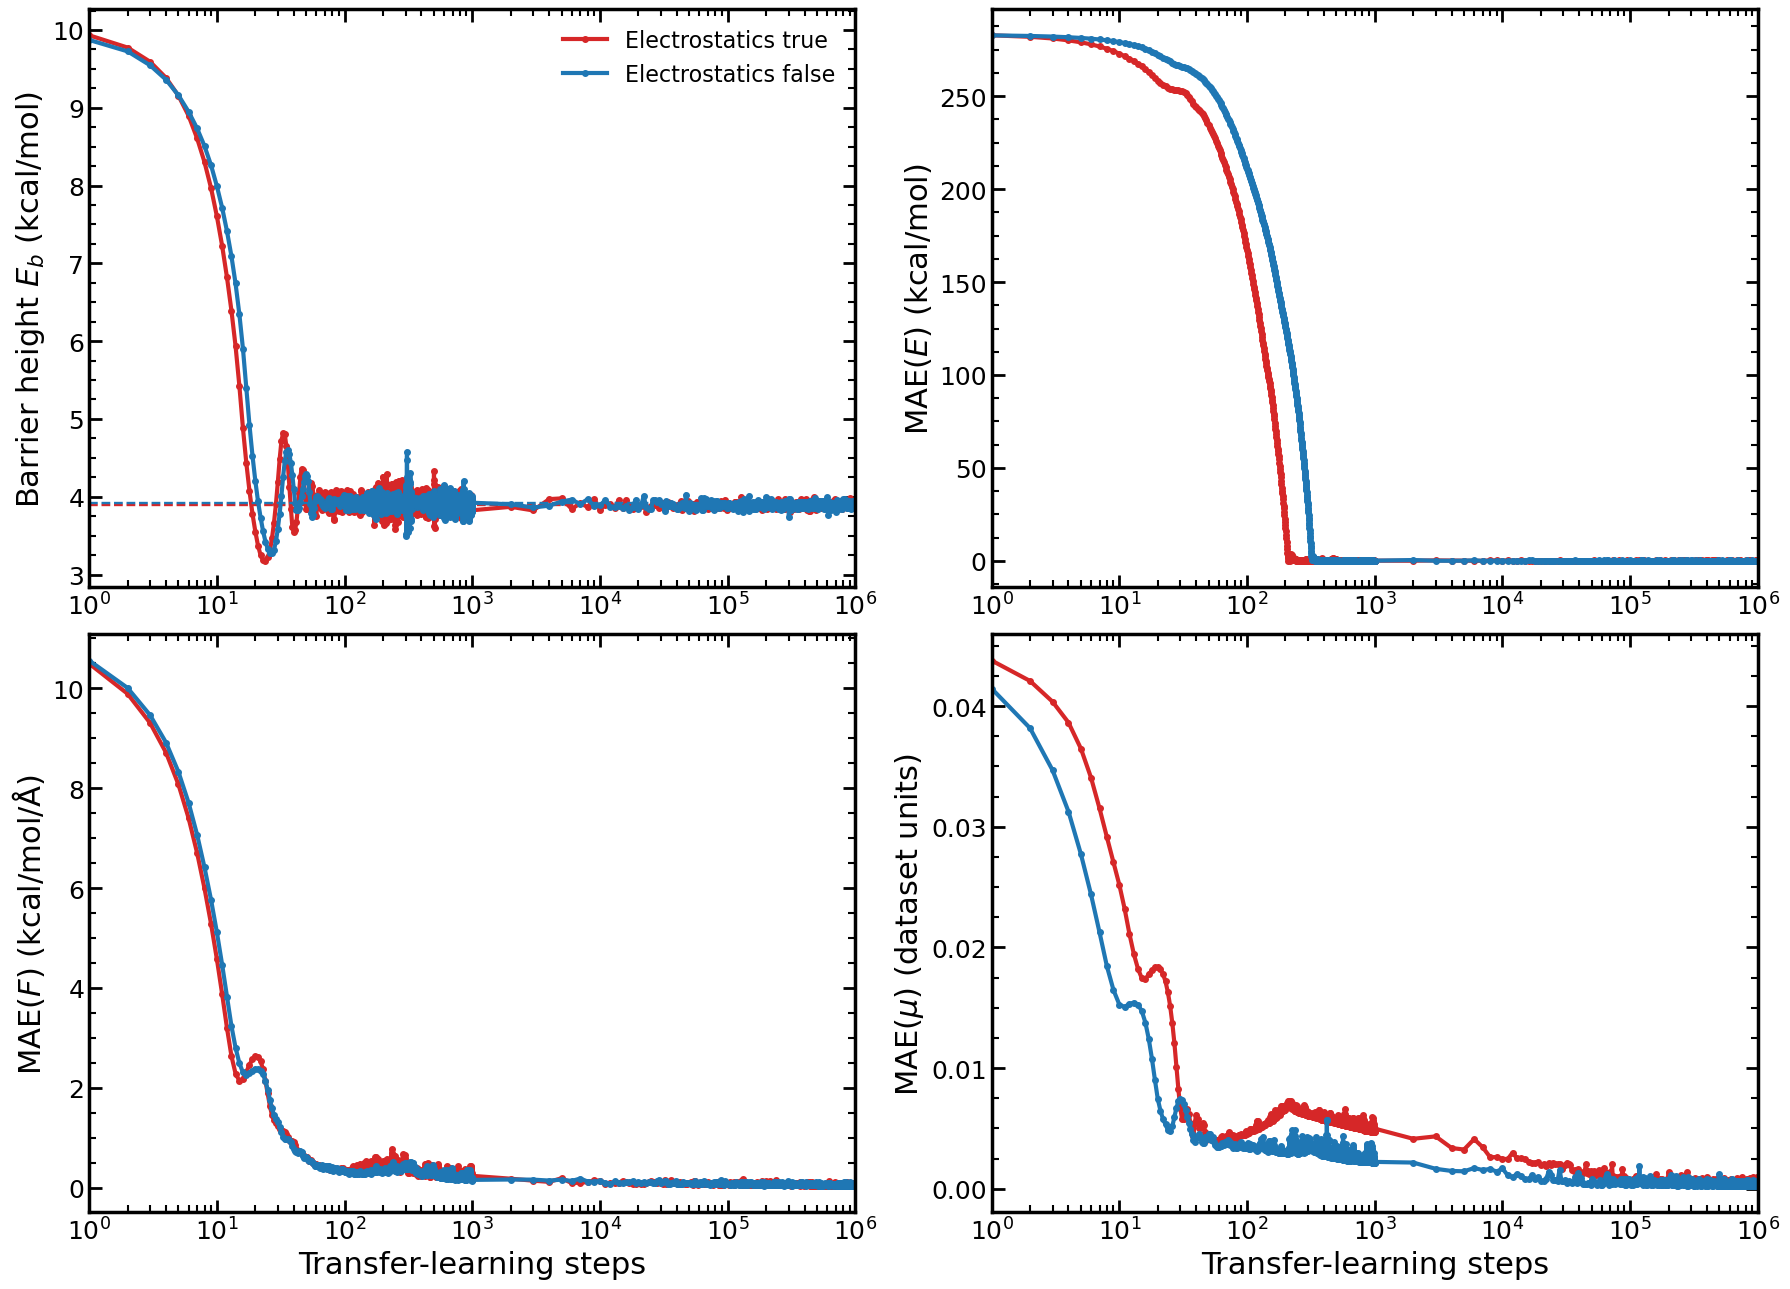

In [9]:
from pathlib import Path
import sys

XAI_ROOT = Path.home() / "XAI"
sys.path.insert(0, str(XAI_ROOT))

# Reload changes to the class automatically
%load_ext autoreload
%autoreload 2

from xai_data_pipeline import XAIDataPipeline

# ============================================================
# DATA OPTIONS
# ============================================================

EXTRACT = False       # True = refresh from original files
SHOW_DATA = True      # Display 9-column pandas DataFrame
SAVE_MERGED = True

# ============================================================
# PLOT OPTIONS
# ============================================================

SHOW_PLOT = True
SAVE_PLOT = True
SHOW_GRID = False
SHOW_REFERENCE = True
SHOW_LEGEND = True

REFERENCE_CHECKPOINT = 1000000

# None = all checkpoints
SELECTED_CHECKPOINTS = None

# ============================================================
# INDIVIDUAL PANEL ZOOM
# ============================================================

RANGES = {
    "Eb": {
        "x": (1, 1000000),
        "y": None,
    },

    "EMAE": {
        "x": (1, 1000000),
        "y": None #(0, 200),
    },

    "FMAE": {
        "x": (1, 1000000),
        "y": None,
    },

    "DMAE": {
        "x": (1, 1000000),
        "y": None,
    },
}

# ============================================================
# FIGURE SETTINGS
# ============================================================

FIGSIZE = (18, 13)

COLORS = ("tab:red", "tab:blue")

LABEL_SIZE = 22
TICK_SIZE = 18
LEGEND_SIZE = 16

LINE_WIDTH = 3.0
MARKER_SIZE = 4.0
SPINE_WIDTH = 2.5

MAJOR_TICK_LENGTH = 9
MINOR_TICK_LENGTH = 5

MAJOR_TICK_WIDTH = 2.0
MINOR_TICK_WIDTH = 1.5

DPI = 300

OUTPUT_NAME = "barrier_mae_2x2"

# ============================================================
# RUN
# ============================================================

analysis = XAIDataPipeline(xai_root=XAI_ROOT)

df = analysis.run(
    extract=EXTRACT,
    show_data=SHOW_DATA,
    save_merged=SAVE_MERGED,
    show_plot=SHOW_PLOT,
    save_plot=SAVE_PLOT,
    show_grid=SHOW_GRID,
    show_reference=SHOW_REFERENCE,
    show_legend=SHOW_LEGEND,
    reference_checkpoint=REFERENCE_CHECKPOINT,
    selected_checkpoints=SELECTED_CHECKPOINTS,
    ranges=RANGES,
    figsize=FIGSIZE,
    colors=COLORS,
    label_size=LABEL_SIZE,
    tick_size=TICK_SIZE,
    legend_size=LEGEND_SIZE,
    line_width=LINE_WIDTH,
    marker_size=MARKER_SIZE,
    spine_width=SPINE_WIDTH,
    major_tick_length=MAJOR_TICK_LENGTH,
    minor_tick_length=MINOR_TICK_LENGTH,
    major_tick_width=MAJOR_TICK_WIDTH,
    minor_tick_width=MINOR_TICK_WIDTH,
    dpi=DPI,
    output_name=OUTPUT_NAME,
)

<div style="border: 4px solid navy; border-radius: 8px; padding: 16px 20px; background-color: lightblue; color: black;">


# Cell 2

---

## Correlation Between Energy Barrier ($E_{\rm b}$) and Energy Prediction Error

While the preceding analysis examines the convergence of individual physical quantities as functions of the transfer-learning steps $N$, this analysis investigates the relationship between the predicted energy barrier $E_{\rm b}$ and the energy mean absolute error, MAE($E_{\rm i}$).

By comparing these quantities across transfer-learning checkpoints, we examine whether a reduction in the overall energy prediction error is accompanied by an improvement in the predicted barrier height. We establish that along the transfer-learning steps $N$, the model first learns the conformational energy ca. $20^{\rm th}$ checkpoint and around $200^{\rm th}$ checkpoint the MAE($E_{\rm i}$) converges, indicating final adjustment to the CCSD(T) energy scale. This illustrates that $TL^{\rm CCSD(T)}_{\rm HF}$ is a 2 staged learning process.

### Computational Implementation

The analysis is performed using the `BarrierMAEScatter` class defined in `xai_barrier_scatter.py`.

The computational workflow consists of three stages:

1. **Data extraction:** The class obtains the predicted energy barriers and corresponding energy MAEs for the selected transfer-learning checkpoints. The analysis considers models with and without explicit electrostatic contributions, where the corresponding data are available.

2. **Data organization:** The energy barriers and MAEs are associated with their respective checkpoint numbers and organized into paired numerical datasets for subsequent analysis.

3. **Visualization:** A scatter plot is generated with MAE($E_{\rm i}$) on the horizontal axis and $E_{\rm b}$ on the vertical axis. Each point represents a transfer-learning checkpoint, allowing the evolution of the relationship between prediction error and barrier height to be examined.

The Jupyter cell provides control over checkpoint selection, axis limits, marker properties, figure dimensions, and output settings.

**Implementation:** `~/XAI/xai_barrier_scatter.py`  
**Processed data:** `~/XAI/data/`  
**Reference checkpoint:** $N=10^6$

---

</div>


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


/mmhome/chaton/XAI/xai_barrier_scatter.py:235: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(
/mmhome/chaton/XAI/xai_barrier_scatter.py:336: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.grid(
/mmhome/chaton/XAI/xai_barrier_scatter.py:235: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(
/mmhome/chaton/XAI/xai_barrier_scatter.py:336: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.grid(


Saved: /mmhome/chaton/XAI/data/mae_vs_barrier_both.png
Saved: /mmhome/chaton/XAI/data/mae_vs_barrier_both.pdf


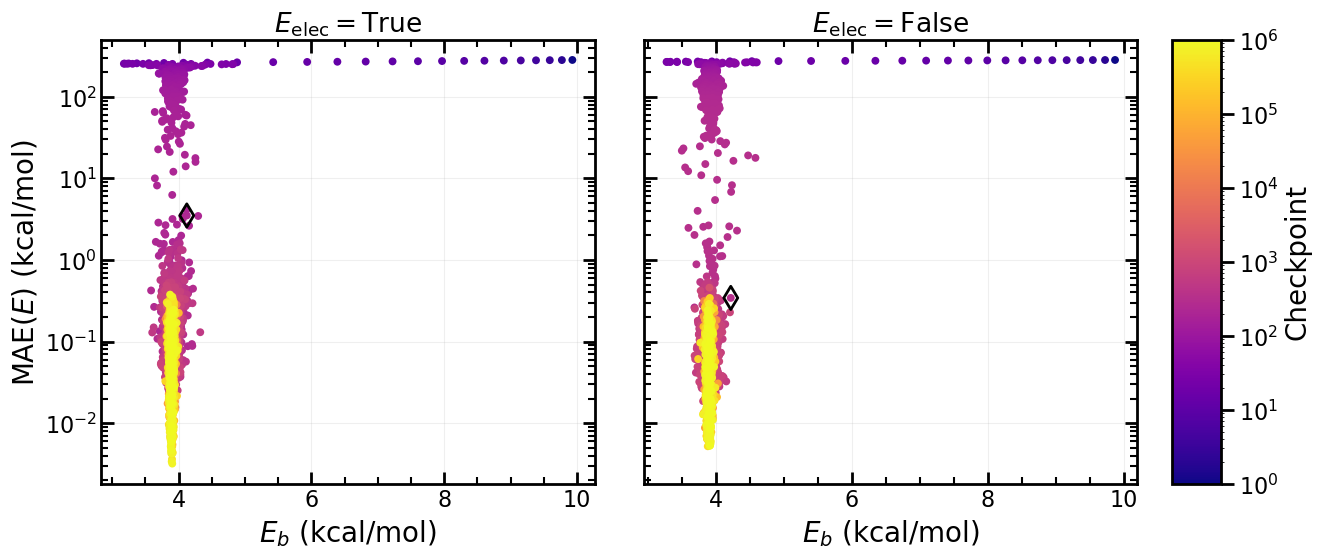

In [10]:

from pathlib import Path
import sys

XAI_ROOT = Path.home() / "XAI"

if str(XAI_ROOT) not in sys.path:
    sys.path.insert(0, str(XAI_ROOT))

%load_ext autoreload
%autoreload 2

from xai_barrier_scatter import BarrierMAEScatter

# ============================================================
# MODEL SELECTION
# ============================================================

PLOT_MODE = "both"  # "both", "true", "false"

# ============================================================
# DISPLAY / SAVE OPTIONS
# ============================================================

SHOW_PLOT = True
SAVE_PLOT = True

SHOW_COLORBAR = True
SHOW_HIGHLIGHTS = True
SHOW_GRID = False

OUTPUT_NAME = "mae_vs_barrier"

# ============================================================
# AXIS RANGES
# ============================================================

# None = automatic limits
# Or specify an independent range for each model

XLIM = None

# Example:
# XLIM = {
#     "true": (3.0, 10.0),
#     "false": (3.0, 10.0),
# }

YLIM = None

# Example:
# YLIM = {
#     "true": (1e-3, 1e3),
#     "false": (1e-3, 1e3),
# }

# ============================================================
# FIGURE SIZE
# ============================================================

FIGSIZE = (14, 6)

# ============================================================
# FIGURE LAYOUT
# ============================================================

LEFT = 0.12
RIGHT = 0.86

BOTTOM = 0.16
TOP = 0.90

WSPACE = 0.10

# ============================================================
# COLORBAR LAYOUT
# ============================================================

COLORBAR_PAD = 0.025
COLORBAR_FRACTION = 0.035
COLORBAR_LABEL_SIZE = 20

# ============================================================
# COLOR MAP
# ============================================================

CMAP = "plasma"

# ============================================================
# HIGHLIGHTED CHECKPOINTS
# ============================================================

HIGHLIGHT_TRUE = (18, 212)
HIGHLIGHT_FALSE = (18, 321)

# ============================================================
# MARKER SETTINGS
# ============================================================

MARKER_SIZE = 32
HIGHLIGHT_SIZE = 140

# ============================================================
# FONT SIZES
# ============================================================

LABEL_SIZE = 20
TICK_SIZE = 16
TITLE_SIZE = 19

# ============================================================
# AXES AND TICKS
# ============================================================

SPINE_WIDTH = 2.0

MAJOR_TICK_LENGTH = 9
MINOR_TICK_LENGTH = 5

MAJOR_TICK_WIDTH = 2.0
MINOR_TICK_WIDTH = 1.5

# ============================================================
# OUTPUT
# ============================================================

DPI = 300

# ============================================================
# RUN FIGURE 2
# ============================================================

analysis = BarrierMAEScatter(
    xai_root=XAI_ROOT
)

analysis.plot(
    mode=PLOT_MODE,

    show_plot=SHOW_PLOT,
    save_plot=SAVE_PLOT,
    output_name=OUTPUT_NAME,

    figsize=FIGSIZE,
    cmap=CMAP,

    xlim=XLIM,
    ylim=YLIM,

    marker_size=MARKER_SIZE,
    highlight_size=HIGHLIGHT_SIZE,

    show_highlights=SHOW_HIGHLIGHTS,
    show_colorbar=SHOW_COLORBAR,
    show_grid=SHOW_GRID,

    highlight_true=HIGHLIGHT_TRUE,
    highlight_false=HIGHLIGHT_FALSE,

    label_size=LABEL_SIZE,
    tick_size=TICK_SIZE,
    title_size=TITLE_SIZE,

    spine_width=SPINE_WIDTH,

    major_tick_length=MAJOR_TICK_LENGTH,
    minor_tick_length=MINOR_TICK_LENGTH,
    major_tick_width=MAJOR_TICK_WIDTH,
    minor_tick_width=MINOR_TICK_WIDTH,

    left=LEFT,
    right=RIGHT,
    bottom=BOTTOM,
    top=TOP,
    wspace=WSPACE,

    colorbar_pad=COLORBAR_PAD,
    colorbar_fraction=COLORBAR_FRACTION,
    colorbar_label_size=COLORBAR_LABEL_SIZE,

    dpi=DPI,
)



<div style="border: 4px solid navy; border-radius: 8px; padding: 16px 20px; background-color: lightblue; color: black;">

## Cell 3

---

## Evolution of Atomic Feature Representations During Transfer Learning

The preceding analyses examine the convergence of predicted physical quantities and the relationship between energy prediction errors and barrier heights. Here, we investigate how the internal atomic feature representations $\mathbf{\mathcal{F}}^{\alpha}_k$ evolve during transfer learning.

Each atom $\alpha$ is represented by a feature vector containing 128 components at a given neural-network module $k$. To characterize the evolution of these representations, we compare the atomic feature vectors obtained at different transfer-learning checkpoints $N$ with those from a reference checkpoint, typically $N_{\rm ref}=10^6$.

The similarity between two feature vectors is quantified using cosine similarity,

$$
\mathbf{\mathcal{P}}_k^{\alpha}(N,N_{\rm ref}) =
\frac{
\mathbf{\mathcal{F}}_{k,N}^{\alpha}
\cdot
\mathbf{\mathcal{F}}_{k,N_{\rm ref}}^{\alpha}
}{
\left\|\mathbf{\mathcal{F}}_{k,N}^{\alpha}\right\|
\left\|\mathbf{\mathcal{F}}_{k,N_{\rm ref}}^{\alpha}\right\|
}.
$$

The cosine similarity measures the alignment of the feature vectors in the 128-dimensional representation space, independently of their magnitudes. Values approaching unity indicate that the representations are increasingly aligned with those of the reference checkpoint. However, this does not necessarily imply convergence of their magnitudes or the corresponding predicted atomic energies.

### Computational Implementation

The analysis is performed using the `FeatureSimilarity` class defined in `xai_feature_similarity.py`.

The computational workflow consists of three stages:

1. **Data extraction:** Atomic feature representations are obtained for the selected transfer-learning checkpoints. The feature vectors are compared with those of the reference checkpoint for corresponding atomic environments, and cosine similarities are evaluated for individual atoms and neural-network modules.

2. **Data organization:** The calculated similarity values are organized according to checkpoint number, atom identity, and module index. The processed numerical results are saved in `~/XAI/data/` for subsequent analysis.

3. **Visualization:** The evolution of cosine similarity is plotted as a function of the transfer-learning steps $N$. Atom-resolved plots allow differences in the evolution of feature representations to be examined across the molecular structure, while module-resolved comparisons provide information about how the representations change at different depths of the neural network.

The Jupyter cell provides adjustable settings for reference checkpoint selection, module selection, atom labels, axis limits, line styles, marker properties, figure dimensions, and output formats. The checkpoint axis is displayed on a logarithmic scale.

By separating feature extraction from visualization, the stored similarity data can be reused to generate alternative figures without repeating the original feature-vector calculations.

**Implementation:** `~/XAI/xai_feature_similarity.py`  
**Processed data:** `~/XAI/data/`  
**Default reference checkpoint:** $N_{\rm ref}=10^6$

---

</div>


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
E_elec=true: 1999 checkpoints -> /mmhome/chaton/XAI/data/feature_similarity/ref_1000000/true.dat
E_elec=false: 1999 checkpoints -> /mmhome/chaton/XAI/data/feature_similarity/ref_1000000/false.dat


/mmhome/chaton/XAI/xai_feature_similarity.py:549: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.grid(show_grid, alpha=0.15)


Saved figures in: /mmhome/chaton/XAI/data/feature_similarity/ref_1000000


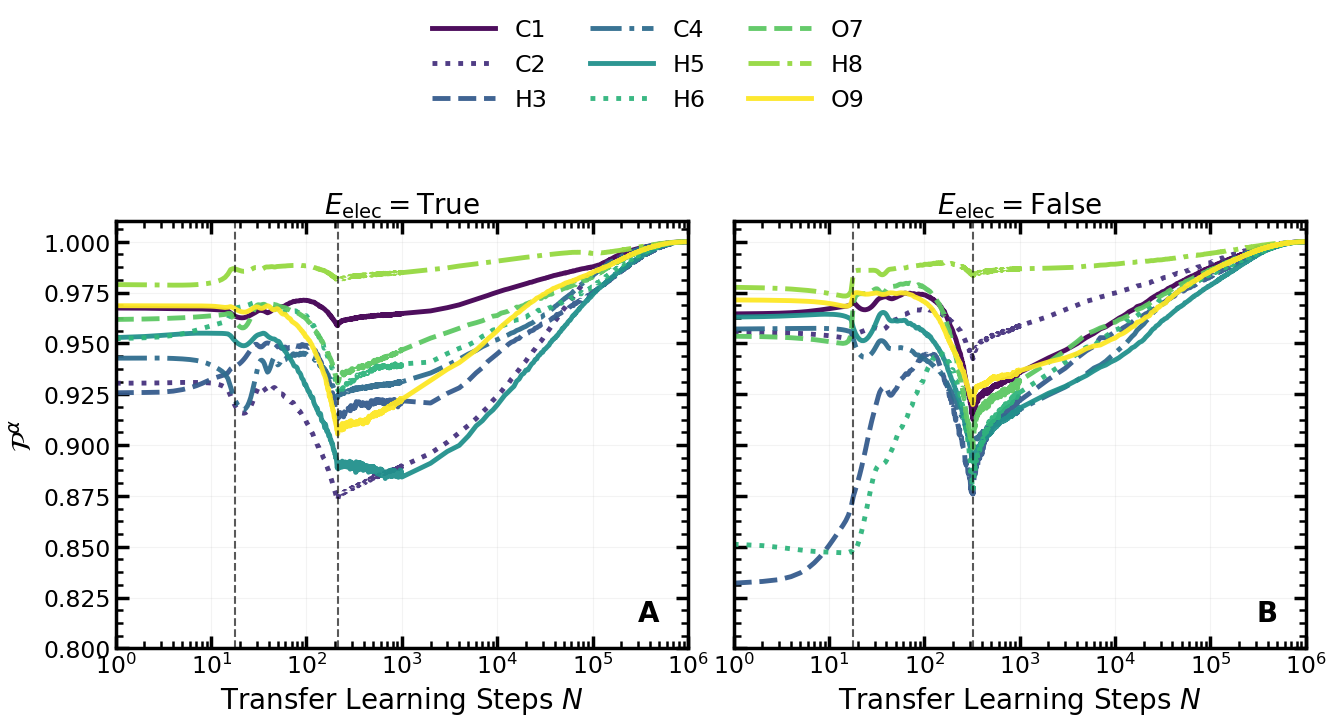

In [6]:

from pathlib import Path
import sys

XAI_ROOT = Path.home() / "XAI"

if str(XAI_ROOT) not in sys.path:
    sys.path.insert(0, str(XAI_ROOT))

%load_ext autoreload
%autoreload 2

from xai_feature_similarity import FeatureSimilarity

# ============================================================
# DATA OPTIONS
# ============================================================

EXTRACT = True       # True first time; False thereafter
SHOW_DATA = False

# ============================================================
# MODEL SELECTION
# ============================================================

PLOT_MODE = "both"   # "both", "true", "false"

# ============================================================
# FEATURE SETTINGS
# ============================================================

REFERENCE_CHECKPOINT = 1000000

FEATURE_KEY = "act_output"
MODULE_INDEX = 4       # 0-based: module 5

NPZ_NAME = "opt_opt_irc_reactant_analysis.npz"

# ============================================================
# DISPLAY AND SAVE
# ============================================================

SHOW_PLOT = True
SAVE_PLOT = True

SHOW_LEGEND = True
SHOW_GRID = False
SHOW_VERTICAL_LINES = True
SHOW_PANEL_LABELS = True

OUTPUT_NAME = "feature_similarity_m5"

# ============================================================
# X AND Y RANGES
# ============================================================

XLIM = (1, 1000000)
YLIM = (0.80, 1.01)

# Independent panel zoom example:
#
# XLIM = {
#     "true": (1, 1000000),
#     "false": (10, 1000),
# }
#
# YLIM = {
#     "true": (0.85, 1.01),
#     "false": (0.80, 1.01),
# }

# ============================================================
# VERTICAL CHECKPOINT MARKERS
# ============================================================

VERTICAL_TRUE = (18, 212)
VERTICAL_FALSE = (18, 321)

VERTICAL_COLOR = "black"
VERTICAL_WIDTH = 1.5
VERTICAL_STYLE = "--"
VERTICAL_ALPHA = 0.65

# ============================================================
# FIGURE SIZE
# ============================================================

FIGSIZE = (14, 7)

# ============================================================
# FIGURE LAYOUT
# ============================================================

LEFT = 0.12
RIGHT = 0.97

BOTTOM = 0.15
TOP = 0.76

WSPACE = 0.08

# ============================================================
# LEGEND
# ============================================================

LEGEND_NCOL = 3

LEGEND_X = 0.50
LEGEND_Y = 1.08

LEGEND_HANDLELENGTH = 2.7

# ============================================================
# FONT SIZES
# ============================================================

LABEL_SIZE = 20
TICK_SIZE = 17
TITLE_SIZE = 20
LEGEND_SIZE = 17

# ============================================================
# CURVES
# ============================================================

LINE_WIDTH = 3.5
ALPHA = 0.95

# ============================================================
# AXES SETTINGS
# ============================================================

SPINE_WIDTH = 2.5

MAJOR_TICK_LENGTH = 9
MINOR_TICK_LENGTH = 5

MAJOR_TICK_WIDTH = 2.5
MINOR_TICK_WIDTH = 1.8

# ============================================================
# OUTPUT RESOLUTION
# ============================================================

DPI = 300

# ============================================================
# RUN
# ============================================================

analysis = FeatureSimilarity(xai_root=XAI_ROOT)

data = analysis.run(
    extract=EXTRACT,
    mode=PLOT_MODE,
    reference_checkpoint=REFERENCE_CHECKPOINT,
    show_data=SHOW_DATA,
    show_plot=SHOW_PLOT,
    save_plot=SAVE_PLOT,
    show_legend=SHOW_LEGEND,
    show_grid=SHOW_GRID,
    show_vertical_lines=SHOW_VERTICAL_LINES,
    show_panel_labels=SHOW_PANEL_LABELS,
    xlim=XLIM,
    ylim=YLIM,
    figsize=FIGSIZE,
    linewidth=LINE_WIDTH,
    alpha=ALPHA,
    label_size=LABEL_SIZE,
    tick_size=TICK_SIZE,
    title_size=TITLE_SIZE,
    legend_size=LEGEND_SIZE,
    spine_width=SPINE_WIDTH,
    major_tick_length=MAJOR_TICK_LENGTH,
    minor_tick_length=MINOR_TICK_LENGTH,
    major_tick_width=MAJOR_TICK_WIDTH,
    minor_tick_width=MINOR_TICK_WIDTH,
    legend_ncol=LEGEND_NCOL,
    legend_x=LEGEND_X,
    legend_y=LEGEND_Y,
    legend_handlelength=LEGEND_HANDLELENGTH,
    left=LEFT,
    right=RIGHT,
    bottom=BOTTOM,
    top=TOP,
    wspace=WSPACE,
    vertical_true=VERTICAL_TRUE,
    vertical_false=VERTICAL_FALSE,
    vertical_color=VERTICAL_COLOR,
    vertical_width=VERTICAL_WIDTH,
    vertical_style=VERTICAL_STYLE,
    vertical_alpha=VERTICAL_ALPHA,
    dpi=DPI,
    output_name=OUTPUT_NAME,
    npz_name=NPZ_NAME,
    feature_key=FEATURE_KEY,
    module_index=MODULE_INDEX,
)


<div style="border: 4px solid navy; border-radius: 8px; padding: 16px 20px; background-color: lightblue; color: black;">


## Cell 4


---

## Evolution of Atomic Feature Representations Along the Minimum-Energy Path (MEP)

Following the analysis of feature representations across transfer-learning checkpoints, we examine their evolution along the minimum-energy path (MEP) of malonaldehyde. The MEP describes the structural transformation associated with intramolecular hydrogen transfer, connecting the reactant state (RS) to the product state (PS) through the transition state (TS).

The analysis considers 600 molecular geometries, with frame 1 corresponding to the RS, frame 300 to the TS, and frame 600 to the PS.

For each molecular configuration $s$, we examine the atomic feature representations $\mathbf{\mathcal{F}}^{\alpha}_{k,s}$ and their relationship to changes in molecular geometry and predicted energy contributions. The magnitude of the feature vector is defined as

$$
\left\|\mathbf{\mathcal{F}}^{\alpha}_{k,s}\right\|
=
\sqrt{
\sum_{j=1}^{128}
\left(\mathcal{F}^{\alpha}_{k,s,j}\right)^2
}.
$$

This quantity characterizes the magnitude of the atomic representation in the 128-dimensional feature space. Its evolution along the MEP is examined alongside the changes in atomic and molecular energies.

We additionally consider variations in selected C–C, C–O, and O–H bond distances and Wiberg bond indices to characterize the accompanying changes in molecular structure and electronic bonding, which has been described in subsequent cell.

### Computational Implementation

The analysis is implemented using the `MEPAnalysis` class defined in `xai_mep.py`.

The computational workflow consists of four stages:

1. **Data extraction:** The class reads the molecular geometries, atomic feature representations, and energy contributions obtained for the configurations along the MEP. Bond distances are determined from the atomic coordinates, while Wiberg bond indices are obtained from separate quantum-chemical calculations where available.

2. **Data organization:** Structural parameters, atomic feature magnitudes, and energy contributions are organized as functions of the MEP frame index. The processed numerical quantities are stored in `~/XAI/MEP/`, allowing subsequent analyses to use a consistent set of molecular configurations.

3. **Feature and energy analysis:** The evolution of atomic feature-vector magnitudes is examined alongside the corresponding atomic and molecular energy contributions. This enables comparisons between changes in the learned representations and changes in the predicted energetics along the reaction pathway.

4. **Structural visualization:** The class provides plotting methods for bond-distance variations, atom-resolved quantities, molecular quantities, and molecular structures with Wiberg bond indices. Structural snapshots can be selected from the RS-to-TS segment or across the complete RS–TS–PS pathway.

### Visualization

The Jupyter cell provides independent plotting controls for the different analyses:

- **Bond-distance analysis:** Evolution of selected interatomic distances along the MEP.
- **Atomic analysis:** Changes in atomic feature-vector magnitudes and energy contributions.
- **Molecular analysis:** Evolution of molecular quantities along the reaction pathway.
- **Wiberg bond-index analysis:** Visualization of structural changes and corresponding bond indices at selected configurations.

Figure dimensions, axis limits, atom selection, line styles, colors, font sizes, and output settings can be adjusted directly from the Jupyter cell.

The separation of data extraction and visualization allows the figures to be regenerated from the processed numerical files without repeatedly loading the original molecular configurations and neural-network output files.

**Implementation:** `~/XAI/xai_mep.py`  
**Processed data:** `~/XAI/MEP/`  
**MEP configurations:** 600  
**Reference structures:** RS (frame 1), TS (frame 300), PS (frame 600)

---

</div>


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Extract 1/600 (  0.2%) | 25.7 frames/s | ETA 23.3s
Extract 25/600 (  4.2%) | 79.9 frames/s | ETA 7.2s
Extract 50/600 (  8.3%) | 99.9 frames/s | ETA 5.5s
Extract 75/600 ( 12.5%) | 119.6 frames/s | ETA 4.4s
Extract 100/600 ( 16.7%) | 135.5 frames/s | ETA 3.7s
Extract 125/600 ( 20.8%) | 149.4 frames/s | ETA 3.2s
Extract 150/600 ( 25.0%) | 164.5 frames/s | ETA 2.7s
Extract 175/600 ( 29.2%) | 175.3 frames/s | ETA 2.4s
Extract 200/600 ( 33.3%) | 181.5 frames/s | ETA 2.2s
Extract 225/600 ( 37.5%) | 187.9 frames/s | ETA 2.0s
Extract 250/600 ( 41.7%) | 194.3 frames/s | ETA 1.8s
Extract 275/600 ( 45.8%) | 201.9 frames/s | ETA 1.6s
Extract 300/600 ( 50.0%) | 204.4 frames/s | ETA 1.5s
Extract 325/600 ( 54.2%) | 210.8 frames/s | ETA 1.3s
Extract 350/600 ( 58.3%) | 213.8 frames/s | ETA 1.2s
Extract 375/600 ( 62.5%) | 214.8 frames/s | ETA 1.0s
Extract 400/600 ( 66.7%) | 217.8 frames/s | ETA 0.9s
Extract 425/600 ( 

/mmhome/chaton/XAI/xai_mep.py:202: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.grid(show_grid,alpha=.15)


Saved figure: /mmhome/chaton/XAI/MEP/bond_time_series


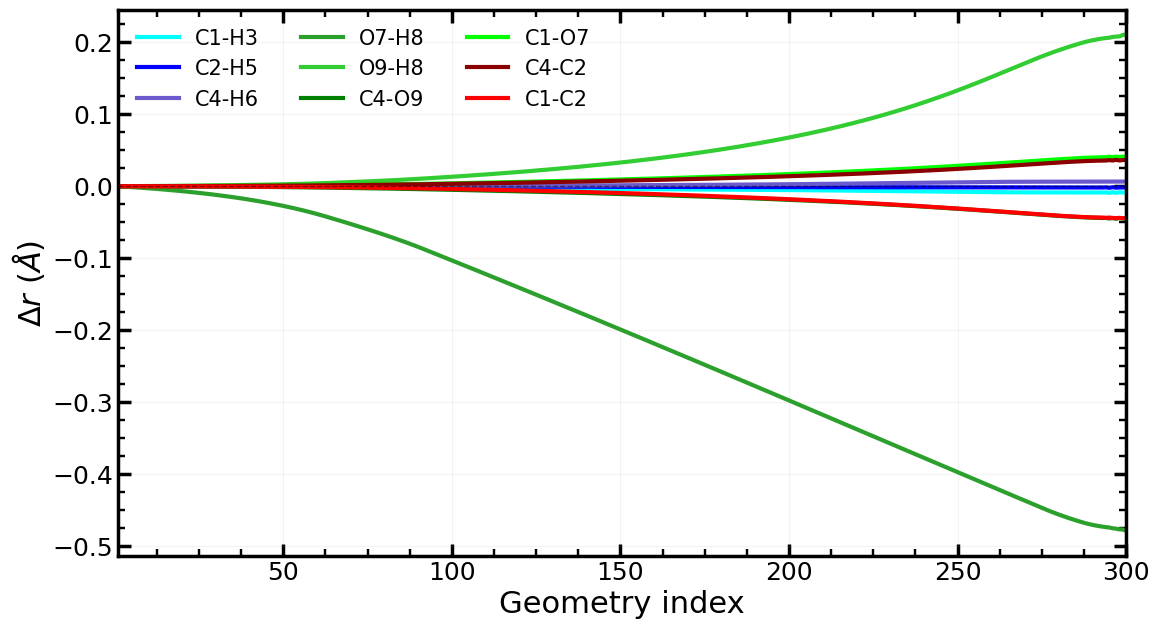

/mmhome/chaton/XAI/xai_mep.py:245: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.grid(show_grid,alpha=.15)


Saved figure: /mmhome/chaton/XAI/MEP/atom_energy_vs_magnitude


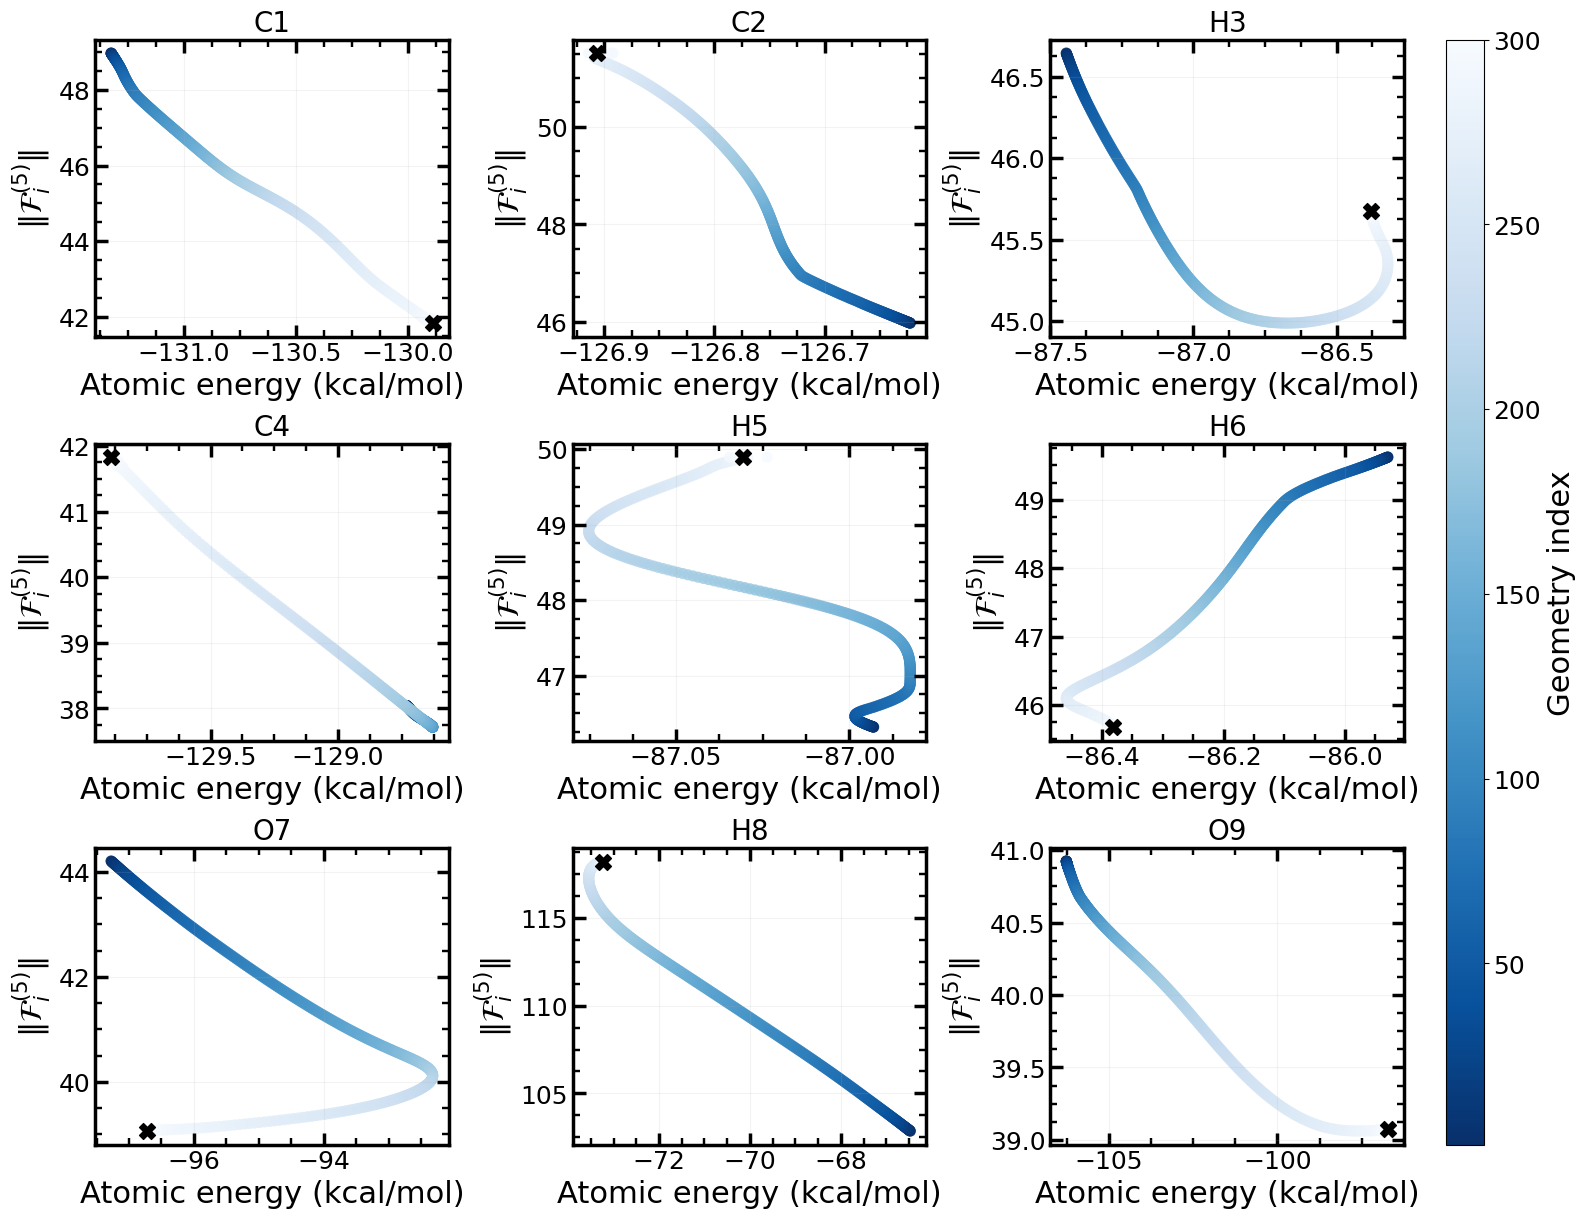

/mmhome/chaton/XAI/xai_mep.py:290: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.grid(show_grid,alpha=.15)


Saved figure: /mmhome/chaton/XAI/MEP/molecular_energy_magnitude


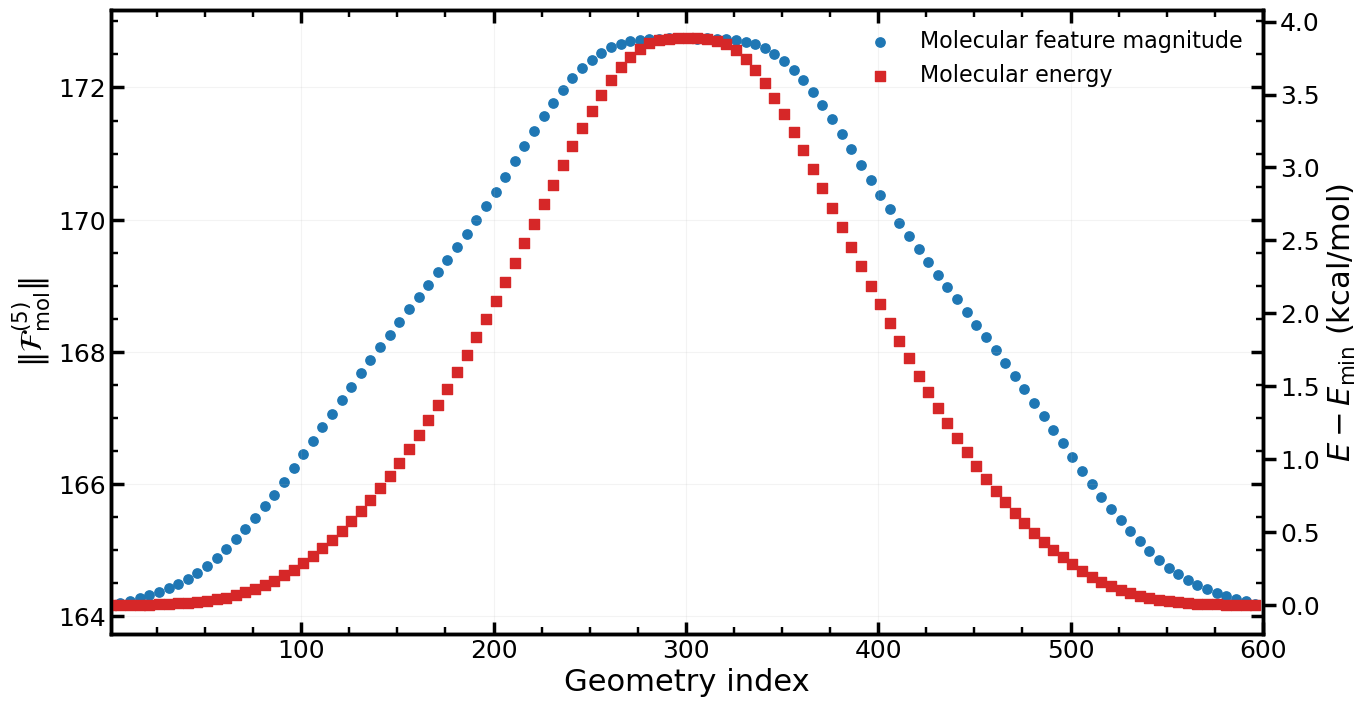

In [23]:

from pathlib import Path
import sys

XAI_ROOT = Path.home() / "XAI"

if str(XAI_ROOT) not in sys.path:
    sys.path.insert(0, str(XAI_ROOT))

%load_ext autoreload
%autoreload 2

from xai_mep import MEPAnalysis

# ============================================================
# DATA EXTRACTION
# ============================================================

EXTRACT = True        # True once, then False
SHOW_DATA = False
PROGRESS_EVERY = 25   # Print speed after every 25 frames

START_FRAME = 1
END_FRAME = 600

FEATURE_KEY = "act"

# ============================================================
# FIGURE SELECTION
# ============================================================

PLOT_BONDS = True
PLOT_ATOMS = True
PLOT_MOLECULAR = True

SHOW_PLOT = True
SAVE_PLOT = True
SHOW_GRID = False

# ============================================================
# FIGURE 1: BOND-LENGTH TIME SERIES
# ============================================================

BOND_FRAME_RANGE = (1, 300)

# True = delta r relative to frame 1
# False = absolute bond lengths
BOND_DELTA = True

BONDS = [
    "C1-H3",
    "C2-H5",
    "C4-H6",
    "O7-H8",
    "O9-H8",
    "C4-O9",
    "C1-O7",
    "C4-C2",
    "C1-C2",
]

BOND_YLIM = None
# Example: (-0.05, 0.05)

BOND_SHOW_LEGEND = True

BOND_FIGSIZE = (12, 7)
BOND_LINE_WIDTH = 3.0

# ============================================================
# FIGURE 2: PER-ATOM ENERGY VS FEATURE MAGNITUDE
# ============================================================

ATOM_FRAME_RANGE = (1, 300)
ATOM_STRIDE = 1

ATOM_ENERGY_MODE = "total"
# "total", "nn", or "elec"

ATOMS = [
    "C1", "C2", "H3",
    "C4", "H5", "H6",
    "O7", "H8", "O9",
]

# Independent axis limits per atom
# Empty dictionary = automatic limits
ATOM_XLIM = {}
ATOM_YLIM = {}

# Examples:
# ATOM_XLIM = {
#     "C1": (-135, -125),
#     "O7": (-110, -90),
# }
#
# ATOM_YLIM = {
#     "C1": (35, 55),
#     "O7": (35, 50),
# }

ATOM_FIGSIZE = (17, 13)

ATOM_CMAP = "Blues_r"
ATOM_MARKER_SIZE = 65
TS_MARKER_SIZE = 130

ATOM_SHOW_COLORBAR = True

# ============================================================
# FIGURE 3: MOLECULAR ENERGY + FEATURE MAGNITUDE
# ============================================================

MOLECULAR_FRAME_RANGE = (1, 600)
MOLECULAR_STRIDE = 5

MOLECULAR_ENERGY_MODE = "total"
# "total", "nn", or "elec"

RELATIVE_ENERGY = True
# True: E - Emin
# False: absolute E

MOLECULAR_MAG_YLIM = None
MOLECULAR_ENERGY_YLIM = None

MOLECULAR_FIGSIZE = (16, 8)

MAG_COLOR = "tab:blue"
ENERGY_COLOR = "tab:red"

MAG_MARKER = "o"
ENERGY_MARKER = "s"

MOLECULAR_MARKER_SIZE = 45
MOLECULAR_SHOW_LEGEND = True

# ============================================================
# COMMON STYLE
# ============================================================

LABEL_SIZE = 22
TICK_SIZE = 18
TITLE_SIZE = 20

SPINE_WIDTH = 2.5

MAJOR_TICK_LENGTH = 9
MINOR_TICK_LENGTH = 5

DPI = 300

# ============================================================
# FIGURE MARGINS
# ============================================================

BOND_LAYOUT = dict(
    left=0.13,
    right=0.97,
    bottom=0.16,
    top=0.94,
)

ATOM_LAYOUT = dict(
    left=0.09,
    right=0.86,
    bottom=0.09,
    top=0.94,
    wspace=0.35,
    hspace=0.36,
)

MOLECULAR_LAYOUT = dict(
    left=0.13,
    right=0.85,
    bottom=0.15,
    top=0.93,
)

# ============================================================
# INITIALIZE
# ============================================================

analysis = MEPAnalysis(
    xai_root=XAI_ROOT,
)

# ============================================================
# EXTRACT OR LOAD DATA
# ============================================================

if EXTRACT:
    tables = analysis.extract(
        start=START_FRAME,
        end=END_FRAME,
        progress_every=PROGRESS_EVERY,
        feature_key=FEATURE_KEY,
    )
else:
    tables = analysis.load()

if SHOW_DATA:
    for name, table in tables.items():
        print(f"\n{name}: {table.shape}")
        display(table)

# ============================================================
# PLOT BOND TIME SERIES
# ============================================================

if PLOT_BONDS:
    analysis.plot_bonds(
        frame_range=BOND_FRAME_RANGE,
        bonds=BONDS,
        delta=BOND_DELTA,
        ylim=BOND_YLIM,
        figsize=BOND_FIGSIZE,
        linewidth=BOND_LINE_WIDTH,
        legend=BOND_SHOW_LEGEND,
        show_grid=SHOW_GRID,
        show=SHOW_PLOT,
        save=SAVE_PLOT,
        label_size=LABEL_SIZE,
        tick_size=TICK_SIZE,
        spine_width=SPINE_WIDTH,
        major_length=MAJOR_TICK_LENGTH,
        minor_length=MINOR_TICK_LENGTH,
        dpi=DPI,
        output_name="bond_time_series",
        **BOND_LAYOUT,
    )

# ============================================================
# PLOT PER-ATOM ENERGY VS MAGNITUDE
# ============================================================

if PLOT_ATOMS:
    analysis.plot_atoms(
        frame_range=ATOM_FRAME_RANGE,
        atoms=ATOMS,
        energy_mode=ATOM_ENERGY_MODE,
        xlimits=ATOM_XLIM,
        ylimits=ATOM_YLIM,
        stride=ATOM_STRIDE,
        figsize=ATOM_FIGSIZE,
        cmap=ATOM_CMAP,
        marker_size=ATOM_MARKER_SIZE,
        ts_marker_size=TS_MARKER_SIZE,
        show_colorbar=ATOM_SHOW_COLORBAR,
        show_grid=SHOW_GRID,
        show=SHOW_PLOT,
        save=SAVE_PLOT,
        label_size=LABEL_SIZE,
        tick_size=TICK_SIZE,
        title_size=TITLE_SIZE,
        spine_width=SPINE_WIDTH,
        major_length=MAJOR_TICK_LENGTH,
        minor_length=MINOR_TICK_LENGTH,
        dpi=DPI,
        output_name="atom_energy_vs_magnitude",
        **ATOM_LAYOUT,
    )

# ============================================================
# PLOT MOLECULAR ENERGY AND MAGNITUDE
# ============================================================

if PLOT_MOLECULAR:
    analysis.plot_molecular(
        frame_range=MOLECULAR_FRAME_RANGE,
        stride=MOLECULAR_STRIDE,
        relative_energy=RELATIVE_ENERGY,
        energy_mode=MOLECULAR_ENERGY_MODE,
        ylim_mag=MOLECULAR_MAG_YLIM,
        ylim_energy=MOLECULAR_ENERGY_YLIM,
        figsize=MOLECULAR_FIGSIZE,
        mag_color=MAG_COLOR,
        energy_color=ENERGY_COLOR,
        mag_marker=MAG_MARKER,
        energy_marker=ENERGY_MARKER,
        marker_size=MOLECULAR_MARKER_SIZE,
        show_legend=MOLECULAR_SHOW_LEGEND,
        show_grid=SHOW_GRID,
        show=SHOW_PLOT,
        save=SAVE_PLOT,
        label_size=LABEL_SIZE,
        tick_size=TICK_SIZE,
        spine_width=SPINE_WIDTH,
        major_length=MAJOR_TICK_LENGTH,
        minor_length=MINOR_TICK_LENGTH,
        dpi=DPI,
        output_name="molecular_energy_magnitude",
        **MOLECULAR_LAYOUT,
    )


<div style="border: 4px solid navy; border-radius: 8px; padding: 16px 20px; background-color: lightblue; color: black;">

## Cell 5

---

### Structural Evolution and Wiberg Bond Indices Along the MEP

To examine the relationship between molecular geometry and electronic bonding during intramolecular hydrogen transfer in malonaldehyde, we visualize selected molecular structures along the minimum-energy path (MEP). Changes in the bonding environment are characterized using Wiberg bond indices (WBI), calculated at the MP2/aug-cc-pVTZ level of theory.

The Wiberg bond index provides a measure of the electron-density-based bond population between two atoms. Although it is related to bond strength and bond multiplicity, it should not be interpreted as a direct measure of either quantity. Following its evolution along the MEP allows us to identify changes in bonding associated with the structural transformation.

The analysis considers molecular configurations along the complete RS–TS–PS pathway or the restricted RS–TS segment. The original MEP consists of 600 configurations, while the reduced structural trajectory contains 100 geometries, corresponding to every sixth configuration of the original pathway.

### Computational Implementation

The analysis is performed using the `MEPAnalysis` class defined in `xai_mep.py`, with the methods `extract_structures()` and `plot_wiberg_structures()`.

1. **Structural data extraction:** Molecular coordinates are read from `100f_latest_combined.xyz`, while Wiberg bond indices are obtained from `wiberg_bond_order_reindexed.dat`. The frame indices are adjusted to maintain consistency between the two datasets.

2. **Structure selection:** A specified number of molecular configurations is selected along the reaction pathway. The `PATH_MODE` variable determines whether the selected structures cover the RS–TS segment (`"rs_ts"`) or the complete RS–TS–PS pathway (`"full"`). Alternatively, individual frames can be specified through `SNAPSHOT_FRAMES`.

3. **Bond-order representation:** Selected interatomic connections are drawn with bond thicknesses determined by their Wiberg bond indices. The bond width is scaled between `BOND_WIDTH_MIN` and `BOND_WIDTH_MAX`, using the specified bond-index interval `BO_MIN` to `BO_MAX`. This provides a visual representation of changes in the electronic bonding environment across the selected geometries.

4. **Visualization:** Molecular structures are arranged in two rows, with optional bond-order annotations, geometric alignment, and additional plots of bond-index changes. The displayed frame labels can be converted to the corresponding original MEP indices using `FRAME_MULTIPLIER = 6`.

The Jupyter cell provides independent controls for the number and selection of structures, bond thicknesses, atomic marker sizes, figure layout, font sizes, and output resolution.

**Implementation:** `~/XAI/xai_mep.py`  
**Structural data:** `100f_latest_combined.xyz`  
**Wiberg bond indices:** `wiberg_bond_order_reindexed.dat`  
**Electronic-structure level:** MP2/aug-cc-pVTZ  
**Available pathways:** RS–TS and RS–TS–PS  
**Default visualization:** 10 structures arranged in two rows  
**Output directory:** `~/XAI/MEP/`

---

</div>


Read 25 XYZ geometries
Read 50 XYZ geometries
Read 75 XYZ geometries
Read 100 XYZ geometries
Staged 100 structures and 100 Wiberg frames in /mmhome/chaton/XAI/MEP
Saved figure: /mmhome/chaton/XAI/MEP/wiberg_structures_rs_ts


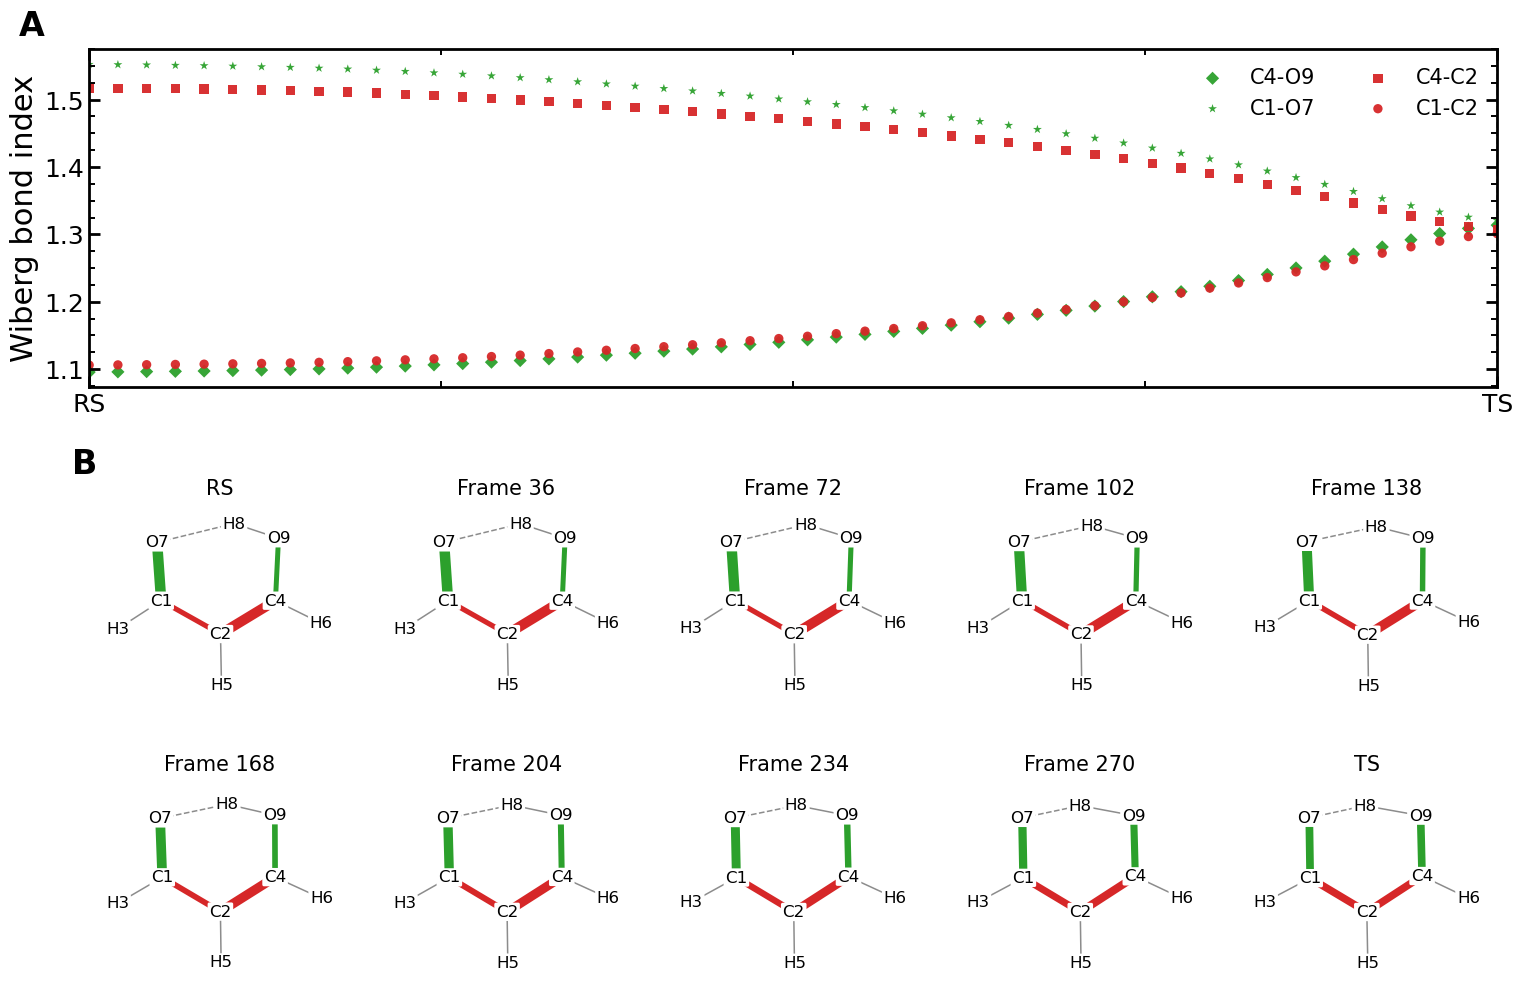

Selected reduced frames: [ 1  6 12 17 23 28 34 39 45 50]


In [7]:
from pathlib import Path
import sys

XAI_ROOT = Path.home() / "XAI"
sys.path.insert(0, str(XAI_ROOT))

%load_ext autoreload
%autoreload 2

from xai_mep import MEPAnalysis

# ============================================================
# DATA EXTRACTION
# ============================================================

EXTRACT_STRUCTURES = True  # First run True, thereafter False

XYZ_FILE = (
    XAI_ROOT
    / "project_feature/modular_energy/mep_yes/"
      "1000000/npz_1m/MEP/100f_latest_combined.xyz"
)

WIBERG_FILE = (
    XAI_ROOT
    / "project_feature/modular_energy/mep_yes/"
      "1000000/npz_1m/MEP/wiberg_bond_order_reindexed.dat"
)

WIBERG_FRAME_OFFSET = 1  # Original Wiberg frame indices start at 0

# ============================================================
# PATH SELECTION
# ============================================================

PATH_MODE = "rs_ts"  # "rs_ts" or "full"

N_STRUCTURES = 10
TS_REDUCED_FRAME = 50

# ============================================================
# ORIGINAL FRAME ANNOTATIONS
# ============================================================

ANNOTATE = "original"   # "original", "reduced"

FRAME_MULTIPLIER = 6
FRAME_OFFSET = 0

# For this XYZ trajectory:
# reduced 1   -> original 6
# reduced 50  -> original 300 (TS)
# reduced 100 -> original 600 (PS)

# None = automatically choose evenly spaced frames
SNAPSHOT_FRAMES = None

# ============================================================
# PLOT OPTIONS
# ============================================================

SHOW_PLOT = True
SAVE_PLOT = True

PLOT_CHANGES = False
SHOW_SNAPSHOT_LINES = False
SHOW_BO_NUMBERS = False
SHOW_HYDROGEN_BONDS = True
ALIGN_GEOMETRIES = True

# ============================================================
# FIGURE SIZE AND LAYOUT
# ============================================================

FIGSIZE = (16, 11)

LEFT = 0.09
RIGHT = 0.97
BOTTOM = 0.07
TOP = 0.92

WSPACE = 0.10
HSPACE = 0.35
UPPER_LOWER_HSPACE = 0.28

TOP_HEIGHT = 1.3
BOTTOM_HEIGHT = 1.85

# ============================================================
# Wiberg / Bond Thickness
# ============================================================

BO_MIN = 0.8
BO_MAX = 1.6

BOND_WIDTH_MIN = 1.0
BOND_WIDTH_MAX = 8.0
BOND_ALPHA = 1.0

MARKER_SIZE = 45
ALPHA = 0.95

# ============================================================
# FONT SIZES
# ============================================================

LABEL_SIZE = 22
TICK_SIZE = 18
LEGEND_SIZE = 15
PANEL_LABEL_SIZE = 24

ATOM_LABEL_SIZE = 12
SNAPSHOT_TITLE_SIZE = 15

LEGEND_NCOL = 2

# ============================================================
# AXES
# ============================================================

SPINE_WIDTH = 2.0
MAJOR_TICK_LENGTH = 8
MINOR_TICK_LENGTH = 4

# ============================================================
# OUTPUT
# ============================================================

OUTPUT_NAME = "wiberg_structures"
DPI = 300

# ============================================================
# INITIALIZE
# ============================================================

analysis = MEPAnalysis(xai_root=XAI_ROOT)

# ============================================================
# STAGE XYZ AND WIBERG DATA
# ============================================================

if EXTRACT_STRUCTURES:
    analysis.extract_structures(
        xyz_file=XYZ_FILE,
        wiberg_file=WIBERG_FILE,
        frame_offset=WIBERG_FRAME_OFFSET,
        progress_every=25,
    )

# ============================================================
# PLOT
# ============================================================

selected_frames = analysis.plot_wiberg_structures(
    path_mode=PATH_MODE,
    n_structures=N_STRUCTURES,
    ts_reduced_frame=TS_REDUCED_FRAME,
    annotate=ANNOTATE,
    frame_multiplier=FRAME_MULTIPLIER,
    frame_offset=FRAME_OFFSET,
    snapshot_frames=SNAPSHOT_FRAMES,
    show=SHOW_PLOT,
    save=SAVE_PLOT,
    figsize=FIGSIZE,
    plot_changes=PLOT_CHANGES,
    show_snapshot_lines=SHOW_SNAPSHOT_LINES,
    show_bo_numbers=SHOW_BO_NUMBERS,
    show_hydrogen_bonds=SHOW_HYDROGEN_BONDS,
    align_geometries=ALIGN_GEOMETRIES,
    bo_min=BO_MIN,
    bo_max=BO_MAX,
    width_min=BOND_WIDTH_MIN,
    width_max=BOND_WIDTH_MAX,
    bond_alpha=BOND_ALPHA,
    marker_size=MARKER_SIZE,
    alpha=ALPHA,
    atom_label_size=ATOM_LABEL_SIZE,
    snapshot_title_size=SNAPSHOT_TITLE_SIZE,
    label_size=LABEL_SIZE,
    tick_size=TICK_SIZE,
    legend_size=LEGEND_SIZE,
    legend_ncol=LEGEND_NCOL,
    panel_label_size=PANEL_LABEL_SIZE,
    spine_width=SPINE_WIDTH,
    major_length=MAJOR_TICK_LENGTH,
    minor_length=MINOR_TICK_LENGTH,
    wspace=WSPACE,
    hspace=HSPACE,
    upper_lower_hspace=UPPER_LOWER_HSPACE,
    left=LEFT,
    right=RIGHT,
    bottom=BOTTOM,
    top=TOP,
    top_height=TOP_HEIGHT,
    bottom_height=BOTTOM_HEIGHT,
    output_name=OUTPUT_NAME,
    dpi=DPI,
)

print("Selected reduced frames:", selected_frames)

<div style="border: 4px solid navy; border-radius: 8px; padding: 16px 20px; background-color: lightblue; color: black;">


## Cell 6

---

## Evolution of Atomic Feature Representations Along Normal-Mode Displacements

Following the analysis of structural transformations along the minimum-energy path (MEP), we investigate how the atomic feature representations $\mathbf{\mathcal{F}}^{\alpha}_k$ respond to systematic geometric perturbations along a selected vibrational normal mode.

Unlike the MEP, which connects molecular configurations along a reaction pathway, normal-mode analysis provides a controlled description of structural displacements around a reference geometry. The atomic coordinates are displaced along a selected normal-mode eigenvector according to

$$
\mathbf{R}(a)=\mathbf{R}_0+a\mathbf{e},
$$

where $\mathbf{R}_0$ denotes the reference molecular geometry, $\mathbf{e}$ is the selected displacement vector, and $a$ is the displacement amplitude. The coordinate convention and normalization of $\mathbf{e}$ determine the units and physical interpretation of $a$.

The analysis examines how these geometric displacements affect the atomic feature representations across the five PhysNet modules (M1–M5). In particular, we consider two complementary quantities:

**1. Feature-vector similarity**

For each atom $\alpha$ and module $k$, the feature vectors predicted by two transfer-learning checkpoints are compared at the same displaced molecular geometry using cosine similarity:

$$
\mathbf{\mathcal{P}}_k^\alpha(a)=
\frac{
\mathbf{\mathcal{F}}^\alpha_{k,N_1}(a)
\cdot
\mathbf{\mathcal{F}}^\alpha_{k,N_2}(a)
}{
\left\|\mathbf{\mathcal{F}}^\alpha_{k,N_1}(a)\right\|
\left\|\mathbf{\mathcal{F}}^\alpha_{k,N_2}(a)\right\|
}.
$$

Here, $N_1=1$ and $N_2=10^6$ represent the initial and final transfer-learning checkpoints. This comparison characterizes the alignment of the learned atomic representations across transfer learning as a function of molecular displacement.

**2. Feature-vector magnitude**

The magnitude of the atomic representation is evaluated independently for the two checkpoints:

$$
\left\|\mathbf{\mathcal{F}}^\alpha_{k,N}(a)\right\|
=
\sqrt{
\sum_{j=1}^{128}
\left(\mathcal{F}^\alpha_{k,N,j}(a)\right)^2
}.
$$

Unlike cosine similarity, the feature-vector magnitude captures changes in the scale of the representation. Together, these two quantities allow directional differences and magnitude differences between the initial and final models to be examined separately.

### Computational Implementation

The analysis is implemented using the `NormalModesAnalysis` class defined in `xai_normal_modes.py`.

The computational workflow consists of three stages:

1. **Data extraction:** Atomic feature vectors are loaded from the normal-mode configurations evaluated using checkpoints $N=1$ and $N=10^6$. Corresponding feature vectors are compared at identical molecular geometries to calculate atom-resolved cosine similarities and feature magnitudes.

2. **Data organization:** The extracted quantities are organized according to displacement amplitude, atom identity, neural-network module, and transfer-learning checkpoint. Numerical results are saved in `~/XAI/data/normal_modes/`, allowing subsequent visualization without repeatedly reading the original neural-network output files.

3. **Visualization:** Two separate figures are generated:
   - **Figure A — Feature similarity:** A 3 × 3 arrangement showing atom-resolved cosine similarity as a function of the normal-mode displacement coordinate. The five neural-network modules are distinguished by individual colors.
   - **Figure B — Feature magnitude:** A 3 × 3 arrangement showing atomic feature-vector magnitudes for the initial and final transfer-learning checkpoints.

### Normal-Mode Configuration

The Jupyter cell allows selection of the reference geometry and vibrational mode. The available configurations include geometries associated with the initial and final transfer-learning checkpoints.

The displacement coordinate is typically sampled over the interval $a\in[-0.5,0.5]$ using 1000 configurations, subject to the displacement convention employed when constructing the normal-mode dataset.

The cell also provides independent controls for axis limits, feature selection, line and scatter representations, smoothing, legend placement, font sizes, and figure dimensions.

**Implementation:** `~/XAI/xai_normal_modes.py`  
**Processed data:** `~/XAI/data/normal_modes/`  
**Compared checkpoints:** $N=1$ and $N=10^6$  
**Neural-network modules:** M1–M5  
**Feature-vector dimensionality:** 128

---

</div>


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Extraction 100/1000 (10.0%) 85.2 frames/s ETA 11s
Extraction 200/1000 (20.0%) 100.1 frames/s ETA 8s
Extraction 300/1000 (30.0%) 113.6 frames/s ETA 6s
Extraction 400/1000 (40.0%) 120.6 frames/s ETA 5s
Extraction 500/1000 (50.0%) 125.4 frames/s ETA 4s
Extraction 600/1000 (60.0%) 122.9 frames/s ETA 3s
Extraction 700/1000 (70.0%) 124.8 frames/s ETA 2s
Extraction 800/1000 (80.0%) 125.6 frames/s ETA 2s
Extraction 900/1000 (90.0%) 125.8 frames/s ETA 1s
Extraction 1000/1000 (100.0%) 127.9 frames/s ETA 0s
Saved: /mmhome/chaton/XAI/data/normal_modes/ckpt_1/mode_oh/comparison_1_vs_1000000.dat
Saved: /mmhome/chaton/XAI/data/normal_modes/ckpt_1/mode_oh/normal_mode_C_cosine.png
Saved: /mmhome/chaton/XAI/data/normal_modes/ckpt_1/mode_oh/normal_mode_C_cosine.pdf


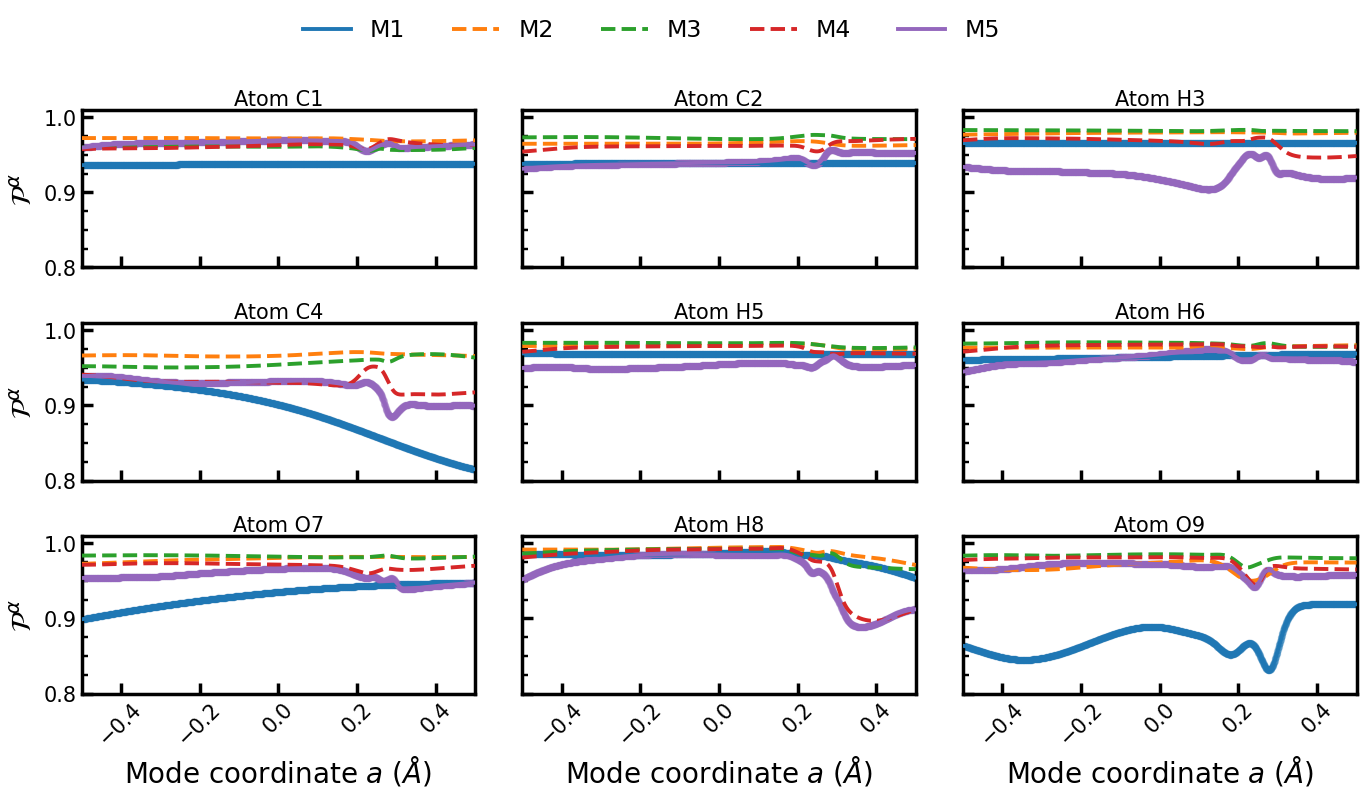

Saved: /mmhome/chaton/XAI/data/normal_modes/ckpt_1/mode_oh/normal_mode_D_magnitude.png
Saved: /mmhome/chaton/XAI/data/normal_modes/ckpt_1/mode_oh/normal_mode_D_magnitude.pdf


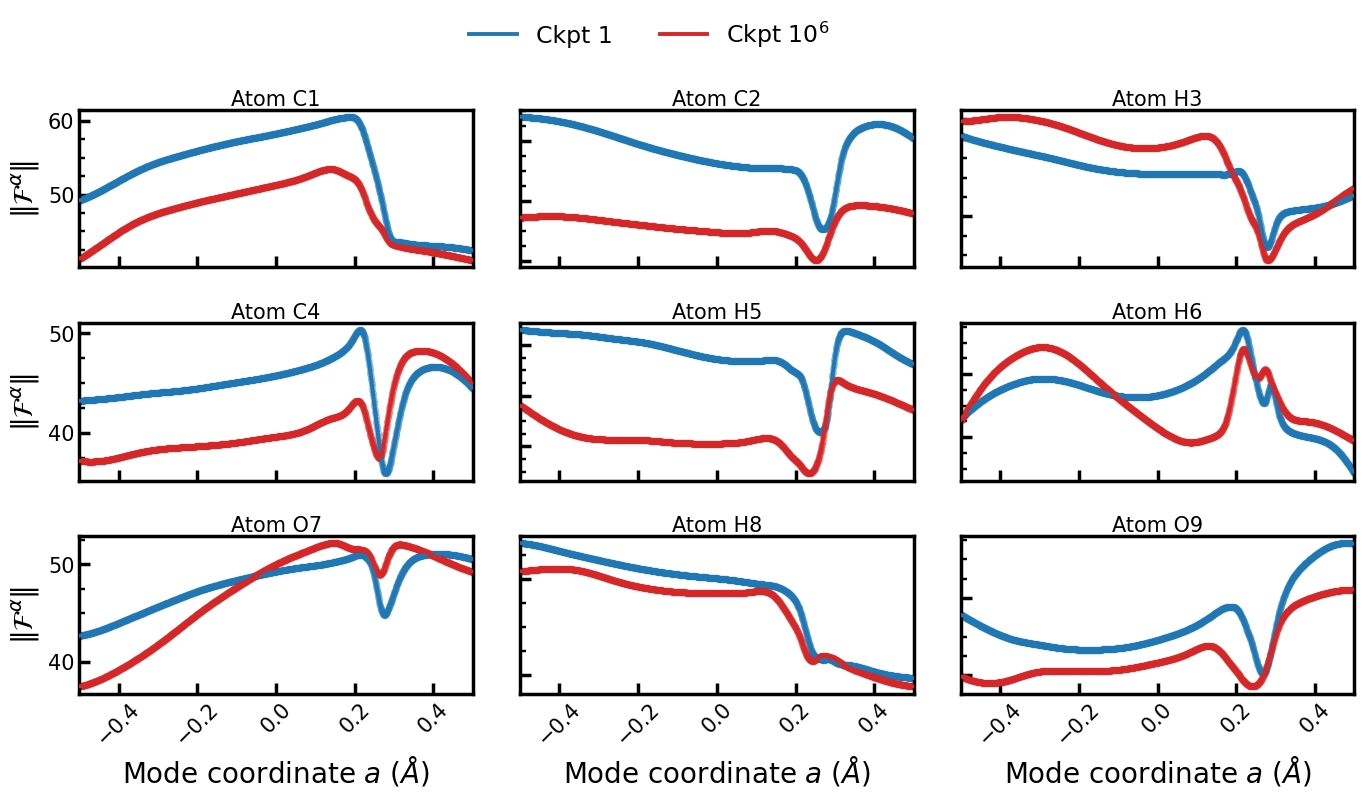

In [8]:
from pathlib import Path
import sys

XAI_ROOT = Path.home() / "XAI"
sys.path.insert(0, str(XAI_ROOT))

%load_ext autoreload
%autoreload 2

from xai_normal_modes import NormalModesAnalysis

# ============================================================
# EXTRACTION
# ============================================================

EXTRACT = True          # True first run; False thereafter

GEOMETRY_TAG = "ckpt_1"  # "ckpt_1" or "ckpt_1000000"
MODE = "mode_oh"

CHECKPOINT_A = 1
CHECKPOINT_B = 1000000

FRAMES = 1000
AMPLITUDE = 0.5
PATH_TYPE = "linear"
FEATURE_KEY = "act"

PROGRESS_EVERY = 100

# ============================================================
# FIGURES
# ============================================================

PLOT_C = True
PLOT_D = True

SHOW_PLOT = True
SAVE_PLOT = True
SHOW_LEGEND = True

# ============================================================
# AXIS RANGES
# ============================================================

XLIM = (-0.5, 0.5)

YLIM_C = (0.80, 1.01)

YLIM_D = None           # Automatic magnitude ranges

# Optional individual limits for D
# YLIM_D = {
#     "C1": (35, 65),
#     "C4": (35, 55),
# }

# ============================================================
# MODULE SELECTION FOR C
# ============================================================

SCATTER_MODULES = (1, 5)
LINE_MODULES = (2, 3, 4)

MODULE_COLORS = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red",
    "tab:purple",
]

# ============================================================
# MAGNITUDE SETTINGS FOR D
# ============================================================

MODULE_MAGNITUDE = 5

MAGNITUDE_COLORS = ("tab:blue", "tab:red")

LABEL_A = "Ckpt 1"
LABEL_B = r"Ckpt $10^6$"

# ============================================================
# CURVES AND MARKERS
# ============================================================

SMOOTHING_WINDOW = 10
LINE_WIDTH = 2.8

SCATTER_SIZE = 18
SCATTER_ALPHA = 0.3

# ============================================================
# FIGURE SIZE
# ============================================================

FIGSIZE_C = (15, 8)
FIGSIZE_D = (15, 8)

# ============================================================
# LEGEND — FIVE COLUMNS FOR FIGURE C
# ============================================================

LEGEND_NCOL = 5
LEGEND_X = 0.50
LEGEND_Y = 0.99
LEGEND_SIZE = 17

# ============================================================
# FIGURE LAYOUT
# ============================================================

LEFT = 0.12
RIGHT = 0.97
BOTTOM = 0.12
TOP = 0.85

WSPACE = 0.12
HSPACE = 0.35

# ============================================================
# FONT SIZES
# ============================================================

LABEL_SIZE = 20
TICK_SIZE = 15
TITLE_SIZE = 15

# ============================================================
# AXES
# ============================================================

SPINE_WIDTH = 2.5
MAJOR_TICK_LENGTH = 8
MINOR_TICK_LENGTH = 4

DPI = 300

# ============================================================
# INITIALIZE
# ============================================================

analysis = NormalModesAnalysis(xai_root=XAI_ROOT)

# ============================================================
# EXTRACT OR LOAD
# ============================================================

if EXTRACT:
    df = analysis.extract(
        geometry_tag=GEOMETRY_TAG,
        mode=MODE,
        checkpoint_a=CHECKPOINT_A,
        checkpoint_b=CHECKPOINT_B,
        frames=FRAMES,
        amplitude=AMPLITUDE,
        path_type=PATH_TYPE,
        feature_key=FEATURE_KEY,
        progress_every=PROGRESS_EVERY,
    )
else:
    df = analysis.load(
        geometry_tag=GEOMETRY_TAG,
        mode=MODE,
        checkpoint_a=CHECKPOINT_A,
        checkpoint_b=CHECKPOINT_B,
    )

# ============================================================
# COMMON PLOT SETTINGS
# ============================================================

COMMON = dict(
    table=df,
    geometry_tag=GEOMETRY_TAG,
    mode=MODE,
    checkpoint_a=CHECKPOINT_A,
    checkpoint_b=CHECKPOINT_B,
    show=SHOW_PLOT,
    save=SAVE_PLOT,
    xlim=XLIM,
    scatter_alpha=SCATTER_ALPHA,
    scatter_size=SCATTER_SIZE,
    line_width=LINE_WIDTH,
    smoothing_window=SMOOTHING_WINDOW,
    show_legend=SHOW_LEGEND,
    legend_x=LEGEND_X,
    legend_y=LEGEND_Y,
    legend_size=LEGEND_SIZE,
    label_size=LABEL_SIZE,
    tick_size=TICK_SIZE,
    title_size=TITLE_SIZE,
    spine_width=SPINE_WIDTH,
    major_tick_length=MAJOR_TICK_LENGTH,
    minor_tick_length=MINOR_TICK_LENGTH,
    left=LEFT,
    right=RIGHT,
    bottom=BOTTOM,
    top=TOP,
    wspace=WSPACE,
    hspace=HSPACE,
    dpi=DPI,
)

# ============================================================
# FIGURE C — COSINE SIMILARITY
# ============================================================

if PLOT_C:
    analysis.plot(
        kind="cosine",
        figsize=FIGSIZE_C,
        ylim_cos=YLIM_C,
        module_colors=MODULE_COLORS,
        cosine_scatter_modules=SCATTER_MODULES,
        cosine_line_modules=LINE_MODULES,
        legend_ncol=LEGEND_NCOL,
        output_name="normal_mode_C",
        **COMMON,
    )

# ============================================================
# FIGURE D — FEATURE MAGNITUDE
# ============================================================

if PLOT_D:
    analysis.plot(
        kind="magnitude",
        figsize=FIGSIZE_D,
        ylim_mag=YLIM_D,
        module_magnitude=MODULE_MAGNITUDE,
        magnitude_colors=MAGNITUDE_COLORS,
        label_a=LABEL_A,
        label_b=LABEL_B,
        output_name="normal_mode_D",
        **COMMON,
    )

<div style="border: 4px solid navy; border-radius: 8px; padding: 16px 20px; background-color: lightblue; color: black;">

## Cell 7

---

## Ensemble Feature Analysis: Molecular Representation Similarity

A complementary analysis of the atomic feature representations $\mathcal{F}^{\alpha}_k$ is performed using an ensemble of molecular configurations extracted from finite-temperature molecular dynamics (MD) simulations.

An ensemble of $M=500$ molecular geometries was sampled at regular intervals from a 100 ps MD trajectory generated using the final transfer-learned PhysNet model, TL$_{\rm HF}^{\rm CCSD(T)}$. For each configuration, the atomic feature representations were evaluated using models at different transfer-learning checkpoints $N$, ranging from the initial HF model ($N=1$) to the final CCSD(T) transfer-learned model ($N=10^6$).

The final checkpoint, $N_{\rm ref}=10^6$, serves as the reference for quantifying changes in the molecular representations throughout transfer learning.

### Construction of the Molecular Representation Matrix

For each transfer-learning checkpoint $N$ and neural-network module $k$, a molecular representation matrix $\mathbf{R}_k^{(N)}$ is constructed from the pairwise scalar products between the feature representations of the sampled molecular configurations:

$$
\mathbf{R}_k^{(N)} =
\begin{pmatrix}
1 & \rho_{12} & \cdots & \rho_{1M} \\
\rho_{21} & 1 & \cdots & \rho_{2M} \\
\vdots & \vdots & \ddots & \vdots \\
\rho_{M1} & \rho_{M2} & \cdots & 1
\end{pmatrix},
$$

where $\rho_{ij}$ denotes the similarity between the feature representations associated with configurations $i$ and $j$ at a given checkpoint and module.

The unique off-diagonal elements of the upper triangular matrix are collected into a column vector,

$$
\mathbf{y}_k^{(N)} =
\begin{bmatrix}
\rho_{12} \\
\rho_{13} \\
\vdots \\
\rho_{1M} \\
\rho_{23} \\
\vdots \\
\rho_{(M-1)M}
\end{bmatrix}.
$$

For $M=500$ configurations, the resulting vector contains

$$
\frac{M(M-1)}{2}=124750
$$

elements.

### Spearman Rank Correlation

The Spearman rank correlation coefficient is calculated between the vectorized representation matrices at checkpoint $N$ and the final reference checkpoint $N_{\rm ref}=10^6$:

$$
\rho_k\left(\mathbf{y}^{(N)},\mathbf{y}^{(10^6)}\right)
=
\operatorname{corr}_{\rm Pearson}
\left[
\operatorname{rank}\left(\mathbf{y}_k^{(N)}\right),
\operatorname{rank}\left(\mathbf{y}_k^{(10^6)}\right)
\right].
$$

This quantity measures the extent to which the ordering of pairwise molecular similarities is preserved during transfer learning. Values approaching unity indicate that the relative ordering of the molecular representations becomes increasingly consistent with the final model.

### Scalar-Product Similarity

As a complementary measure, the scalar product between the vectorized molecular representation matrices is considered:

$$
\sigma_k\left(\mathbf{y}^{(N)},\mathbf{y}^{(10^6)}\right)
=
\left\langle
\mathbf{y}_k^{(N)},
\mathbf{y}_k^{(10^6)}
\right\rangle.
$$

This provides a direct comparison of the corresponding entries of the molecular representation matrices.

### Computational Implementation

The analysis is performed using the `XAISpearman` class defined in `xai_spearman.py`.

1. **Ensemble data:** The precomputed representation matrices are read from the `md_yes` and `md_no` datasets, corresponding to PhysNet models with and without explicit electrostatic energy contributions.

2. **Vectorization:** The 124,750 unique off-diagonal elements of each $500\times500$ representation matrix are extracted as the vector $\mathbf{y}_k^{(N)}$.

3. **Checkpoint comparison:** Each vector is compared with its corresponding reference vector at $N_{\rm ref}=10^6$. Comparisons are performed independently for each neural-network module and electrostatic model variant.

4. **Numerical storage:** The calculated similarity coefficients are saved in `~/XAI/data/spearman/`, allowing subsequent plotting without repeatedly loading the original representation matrices.

The `FULL_FEATURE_PICTURE` variable controls whether the analysis considers the final interaction module (M5) alone or all five modules (M1–M5). The `EXTRACT_KRM` option determines whether the similarity coefficients are recalculated or loaded from the previously processed numerical data.

**Implementation:** `~/XAI/xai_spearman.py`  
**MD ensemble:** 500 configurations sampled from 100 ps  
**Representation matrix:** $500\times500$  
**Comparison-vector length:** 124,750  
**Reference checkpoint:** $N_{\rm ref}=10^6$  
**Processed data:** `~/XAI/data/spearman/`

---

</div>


In [14]:

from pathlib import Path
import sys

XAI_ROOT = Path.home() / "XAI"

if str(XAI_ROOT) not in sys.path:
    sys.path.insert(0, str(XAI_ROOT))

%load_ext autoreload
%autoreload 2

from xai_spearman import XAISpearman

# ============================================================
# GENERAL SETTINGS
# ============================================================

REFERENCE_CHECKPOINT = 1000000

# False = M5 only
# True  = all five modules
FULL_FEATURE_PICTURE = False
#EXTRACT_KRM = False
#FULL_FEATURE_PICTURE = True

# ============================================================
# EXTRACTION SETTINGS
# ============================================================

EXTRACT_KRM = True
EXTRACT_AUX = True

PROGRESS_EVERY = 5

# ============================================================
# ELECTROSTATIC ENERGY SOURCE
# ============================================================

# "auto"   = NPZ files first, series DAT files as fallback
# "npz"    = NPZ files only
# "series" = series DAT files only

ELEC_SOURCE = "auto"

SERIES_ROOT = None

FRAME_MIN = 1
FRAME_MAX = 1000
FRAME_STRIDE = 1

# ============================================================
# INITIALIZE
# ============================================================

analysis = XAISpearman(
    xai_root=XAI_ROOT
)

# ============================================================
# EXTRACT / LOAD KRM DATA
# ============================================================

if EXTRACT_KRM:

    df = analysis.extract(
        reference_checkpoint=REFERENCE_CHECKPOINT,
        full_feature_picture=FULL_FEATURE_PICTURE,
        progress_every=PROGRESS_EVERY,
    )

else:

    df = analysis.load(
        reference_checkpoint=REFERENCE_CHECKPOINT
    )

print("\nKRM data:")
display(df.head())

# ============================================================
# EXTRACT / LOAD ELECTROSTATIC ENERGY AND MAE
# ============================================================

if EXTRACT_AUX:

    aux = analysis.extract_auxiliary(
        frame_min=FRAME_MIN,
        frame_max=FRAME_MAX,
        frame_stride=FRAME_STRIDE,
        elec_source=ELEC_SOURCE,
        series_root=SERIES_ROOT,
        strict_elec=True,
        progress_every=PROGRESS_EVERY,
    )

else:

    aux = analysis.load_auxiliary()

print("\nAuxiliary data:")
display(aux.head())

print("\nData directory:")
print(XAI_ROOT / "data/spearman")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Extraction 44/44 (100.0%) | 31.97 files/s | ETA 0s

Saved 264 rows: /mmhome/chaton/XAI/data/spearman/metrics_ref_1000000.dat

KRM data:


,checkpoint,model,module,cosine,spearman
0,1,False,5,0.999927,0.990546
1,1,False,5,0.999927,0.990546
2,1,False,5,0.999927,0.990546
3,1,False,5,0.999927,0.990546
4,1,False,5,0.999927,0.990546


Electrostatic extraction: 1/22 checkpoints; latest 1: 500 frames (npz)
Electrostatic extraction: 5/22 checkpoints; latest 20: 500 frames (npz)
Electrostatic extraction: 10/22 checkpoints; latest 100: 500 frames (npz)
Electrostatic extraction: 15/22 checkpoints; latest 1000: 500 frames (npz)
Electrostatic extraction: 20/22 checkpoints; latest 500000: 500 frames (npz)
Electrostatic extraction: 22/22 checkpoints; latest 1000000: 500 frames (npz)
Saved: /mmhome/chaton/XAI/data/spearman/auxiliary_mae_elec.dat

Auxiliary data:


,checkpoint,EMAE_true_kcalmol,EMAE_false_kcalmol,mean_Eelec_eV,n_elec_frames,elec_source
0,1,282.732365,282.693283,-5.016050,500,npz
1,5,278.945056,281.300351,-5.085751,500,npz
2,10,272.868118,279.063836,-5.215305,500,npz
3,15,265.957629,276.278057,-5.388077,500,npz
4,20,258.373706,272.230103,-5.556148,500,npz



Data directory:
/mmhome/chaton/XAI/data/spearman


<div style="border: 4px solid navy; border-radius: 8px; padding: 16px 20px; background-color: lightblue; color: black;">


## Cell 8 
---

##  Evolution of Ensemble Feature Similarity During Transfer Learning

Using the pairwise similarity vectors constructed in Cell 7, we examine how the learned molecular feature representations evolve during transfer learning. For each checkpoint $N$, the Spearman rank correlation and cosine similarity are evaluated with respect to the final transfer-learned model at $N_{\rm ref}=10^6$.

The two measures provide complementary information. **Spearman rank correlation** quantifies the preservation of the relative ordering of pairwise molecular similarities, whereas **cosine similarity** characterizes the directional alignment between the corresponding similarity vectors. Their evolution across transfer-learning checkpoints allows us to investigate changes in the relationships between molecular configurations encoded by the neural network.

### Visualization

The `XAISpearman.plot()` method generates a $2\times2$ figure organized as follows:

| | $E_{\rm elec}=\mathrm{True}$ | $E_{\rm elec}=\mathrm{False}$ |
|---|---|---|
| **Top row** | Spearman rank correlation | Spearman rank correlation |
| **Bottom row** | Cosine similarity | Cosine similarity |

The horizontal axis represents the number of transfer-learning steps $N$ on a logarithmic scale. Each curve corresponds to an individual PhysNet interaction module (M1–M5).

Comparing the two model variants allows us to examine whether the inclusion of explicit electrostatic energy during model training influences the evolution of the learned feature representations.

### Computational Implementation

The figure is generated using the `XAISpearman` class defined in `xai_spearman.py`.

- **Module selection:** `FULL_FEATURE_PICTURE = True` displays all five interaction modules, whereas `False` restricts the analysis to M5.
- **Model selection:** `PLOT_MODE_1` determines whether both electrostatic variants or only one is displayed.
- **Plot configuration:** Axis limits, module colors, markers, font sizes, legends, and subplot spacing are controlled independently from the Jupyter cell.
- **Output:** The figure is saved in PNG and PDF formats using the numerical data extracted in Cell 7.

**Plotting method:** `XAISpearman.plot()`  
**Reference checkpoint:** $N_{\rm ref}=10^6$  
**Figure layout:** $2\times2$  
**Output directory:** `~/XAI/data/spearman/`

---

Saved: /mmhome/chaton/XAI/data/spearman/figure1_krm_spearman_cosine_m5_both_ref_1000000.png and .pdf


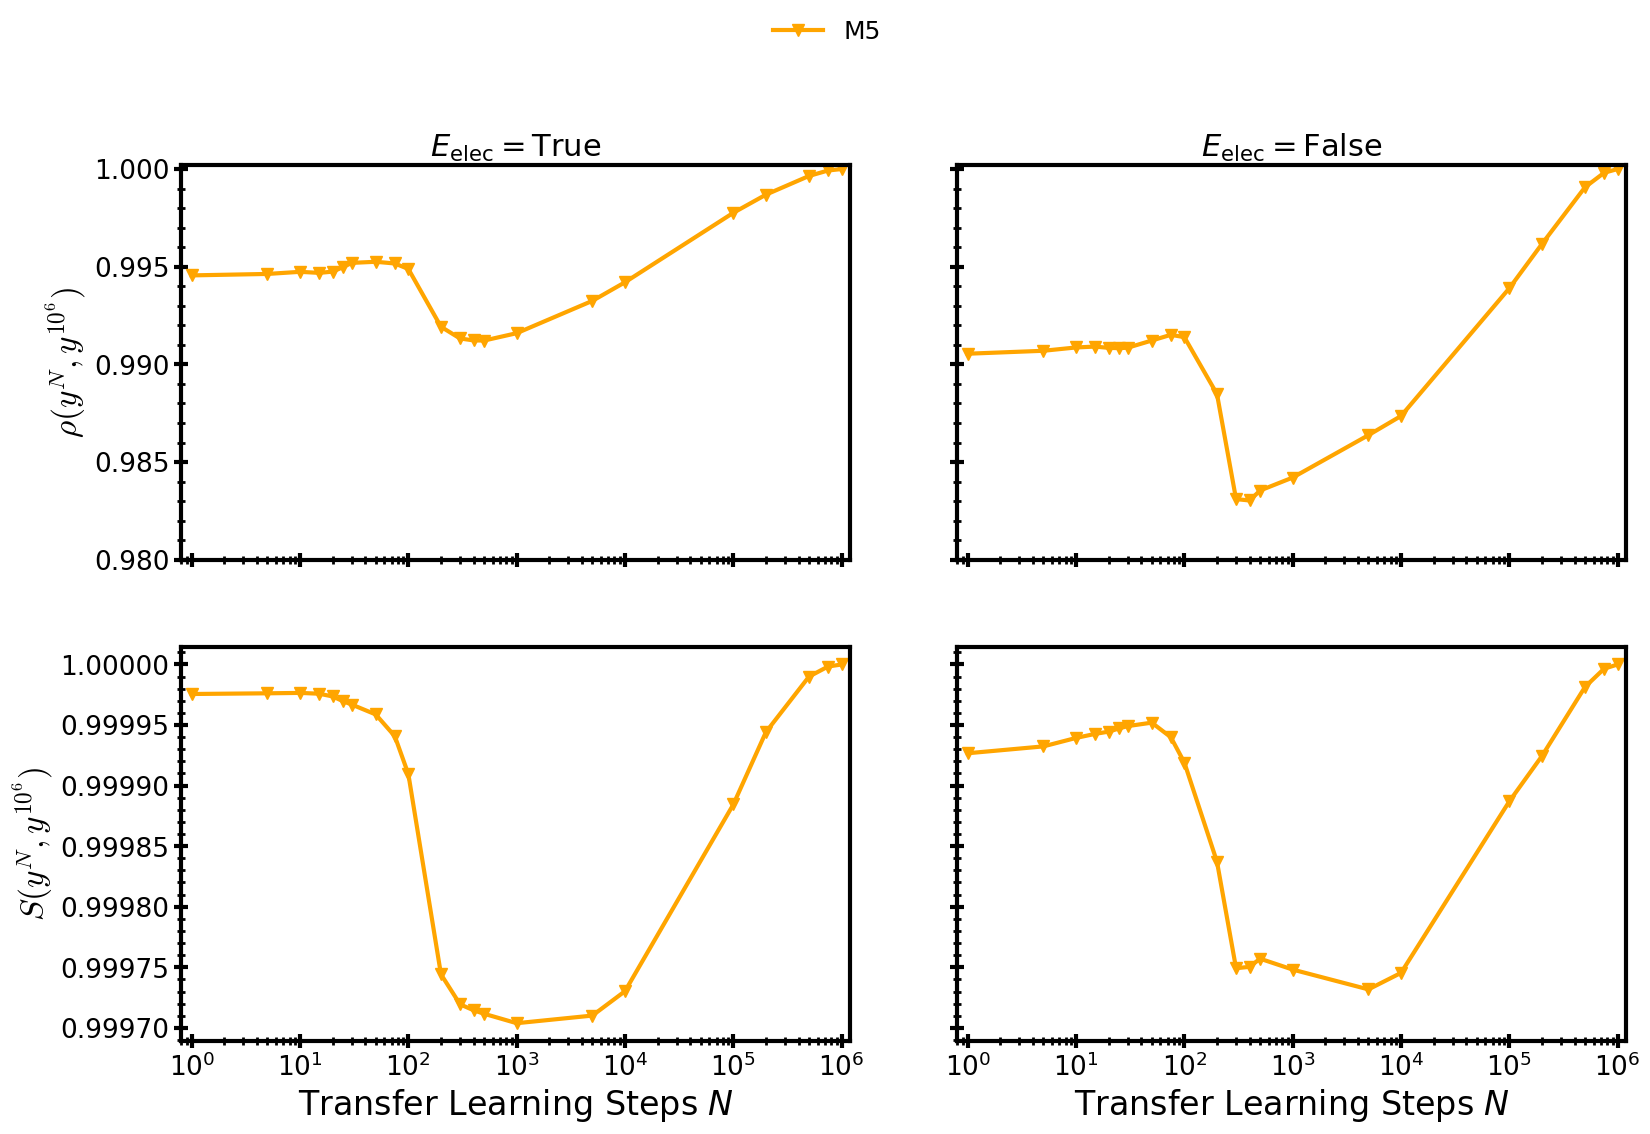

In [15]:
# ============================================================
# FIGURE 1 — 2 × 2 KRM SIMILARITY
# ============================================================

PLOT_FIGURE_1 = True

SHOW_FIGURE_1 = True
SAVE_FIGURE_1 = True

# ============================================================
# FEATURE SELECTION
# ============================================================

# Uses the setting from Cell 1
# FULL_FEATURE_PICTURE = False -> M5 only
# FULL_FEATURE_PICTURE = True  -> M1 to M5

PLOT_MODE_1 = "both"  # "both", "true", "false"

# ============================================================
# AXIS LIMITS
# ============================================================

XLIM_1 = (0.8, 1.2e6)

YLIMITS_1 = {
    "spearman": (0.98, 1.0002),
    "cosine": None,
}

# ============================================================
# FIGURE SIZE
# ============================================================

FIGSIZE_1 = (17, 12)

# ============================================================
# COLORS AND MARKERS — M1 THROUGH M5
# ============================================================

MODULE_COLORS_1 = [
    "blue",
    "red",
    "green",
    "purple",
    "orange",
]

MODULE_MARKERS_1 = [
    "o",
    "s",
    "^",
    "D",
    "v",
]

# ============================================================
# LINES AND MARKERS
# ============================================================

LINE_WIDTH_1 = 3.0
MARKER_SIZE_1 = 8

# ============================================================
# FONTS
# ============================================================

LABEL_SIZE_1 = 24
TICK_SIZE_1 = 19
TITLE_SIZE_1 = 22
LEGEND_SIZE_1 = 18

# ============================================================
# SPINES AND TICKS
# ============================================================

SPINE_WIDTH_1 = 3.0

MAJOR_TICK_LENGTH_1 = 10
MINOR_TICK_LENGTH_1 = 6

MAJOR_TICK_WIDTH_1 = 3.0
MINOR_TICK_WIDTH_1 = 2.0

# ============================================================
# LAYOUT
# ============================================================

LEFT_1 = 0.12
RIGHT_1 = 0.97
BOTTOM_1 = 0.11
TOP_1 = 0.84

WSPACE_1 = 0.16
HSPACE_1 = 0.22

# ============================================================
# LEGEND
# ============================================================

SHOW_LEGEND_1 = True

LEGEND_NCOL_1 = 5
LEGEND_X_1 = 0.50
LEGEND_Y_1 = 0.98

# ============================================================
# OTHER SETTINGS
# ============================================================

SHOW_GRID_1 = False

DPI_1 = 300

OUTPUT_NAME_1 = "figure1_krm_spearman_cosine"

# ============================================================
# PLOT FIGURE 1
# ============================================================

if PLOT_FIGURE_1:

    analysis.plot(
        table=df,
        reference_checkpoint=REFERENCE_CHECKPOINT,
        full_feature_picture=FULL_FEATURE_PICTURE,
        mode=PLOT_MODE_1,
        show_plot=SHOW_FIGURE_1,
        save_plot=SAVE_FIGURE_1,
        figsize=FIGSIZE_1,
        xlim=XLIM_1,
        ylimits=YLIMITS_1,
        colors=MODULE_COLORS_1,
        markers=MODULE_MARKERS_1,
        linewidth=LINE_WIDTH_1,
        markersize=MARKER_SIZE_1,
        label_size=LABEL_SIZE_1,
        tick_size=TICK_SIZE_1,
        title_size=TITLE_SIZE_1,
        legend_size=LEGEND_SIZE_1,
        spine_width=SPINE_WIDTH_1,
        major_tick_length=MAJOR_TICK_LENGTH_1,
        minor_tick_length=MINOR_TICK_LENGTH_1,
        major_tick_width=MAJOR_TICK_WIDTH_1,
        minor_tick_width=MINOR_TICK_WIDTH_1,
        left=LEFT_1,
        right=RIGHT_1,
        bottom=BOTTOM_1,
        top=TOP_1,
        wspace=WSPACE_1,
        hspace=HSPACE_1,
        legend_ncol=LEGEND_NCOL_1,
        legend_x=LEGEND_X_1,
        legend_y=LEGEND_Y_1,
        show_legend=SHOW_LEGEND_1,
        show_grid=SHOW_GRID_1,
        dpi=DPI_1,
        output_name=OUTPUT_NAME_1,
    )

<div style="border: 4px solid navy; border-radius: 8px; padding: 16px 20px; background-color: lightblue; color: black;">


## Cell 9

---

## Relationship Between Ensemble Feature Similarity and Predicted Energetic Properties

Following the analysis of ensemble feature similarity across transfer-learning checkpoints, we investigate its relationship with the predicted energetic properties of the PhysNet models. Specifically, we examine whether changes in the relative similarities between molecular configurations are accompanied by variations in the electrostatic energy contribution and the energy mean absolute error, MAE($E_i$).

The analysis is restricted to the final interaction module (M5), with the final transfer-learned model at $N_{\rm ref}=10^6$ serving as the reference for the ensemble similarity measures.

### Electrostatic Energy

For each transfer-learning checkpoint $N$, the mean molecular electrostatic energy is evaluated over the selected MD configurations:

$$
\left\langle E_{\rm elec}^{(N)}\right\rangle
=
\frac{1}{M}
\sum_{s=1}^{M}
E_{\rm elec}^{(N)}(s),
$$

where $M$ denotes the number of selected molecular configurations and $E_{\rm elec}^{(N)}(s)$ is the electrostatic energy of configuration $s$ predicted by the corresponding model.

The molecular electrostatic energy is obtained by summing the atomic electrostatic contributions:

$$
E_{\rm elec}^{(N)}(s)
=
\sum_{\alpha=1}^{N_{\rm atoms}}
E_{\rm elec}^{\alpha,(N)}(s).
$$

This quantity characterizes the explicit electrostatic contribution to the predicted molecular energy. Its evolution is compared with the ensemble similarity measures to examine whether changes in the learned representations are accompanied by changes in the electrostatic energy contribution.

### Energy Prediction Error

The energy mean absolute error, MAE($E_i$), is evaluated at each transfer-learning checkpoint using the corresponding test-set predictions.

Comparing MAE($E_i$) with the ensemble feature similarity provides a means of examining the relationship between changes in the internal neural-network representations and the accuracy of the predicted molecular energies in the test set.


### Visualization

The `XAISpearman.plot_metrics_with_energy()` method generates two vertically arranged panels, each containing two independent vertical axes.

**Upper panel — Spearman correlation and electrostatic energy**

- **Left axis:** M5 Spearman rank correlation, $\rho_5(N,N_{\rm ref})$, for models with and without explicit electrostatic energy.
- **Right axis:** Mean molecular electrostatic energy, $\langle E_{\rm elec}^{(N)}\rangle$, for the electrostatic model.

**Lower panel — Cosine similarity and energy MAE**

- **Left axis:** M5 cosine similarity, $S_5(N,N_{\rm ref})$, for models with and without explicit electrostatic energy.
- **Right axis:** Energy mean absolute error, MAE($E_i$), for both model variants, displayed on a logarithmic scale.

Solid and dashed curves distinguish models with and without explicit electrostatic contributions. The similarity measures are displayed together with the corresponding energetic quantities to facilitate comparison across transfer-learning checkpoints.

This combined analysis allows us to investigate whether the evolution of the learned ensemble representations is associated with changes in electrostatic energy and improvements in energy prediction accuracy, without assuming a direct causal relationship between these quantities.

### Computational Implementation

The analysis is performed using the `XAISpearman` class defined in `xai_spearman.py`.

1. **Ensemble similarity:** The M5 Spearman correlation and cosine similarity values calculated in Cell 7 are reused without repeating the feature analysis.
2. **Electrostatic energy extraction:** Molecular electrostatic energies are read from the saved PhysNet outputs and averaged over the selected MD configurations.
3. **Energy prediction errors:** The energy MAEs for models with and without electrostatic contributions are loaded from the corresponding test-set error datasets.
4. **Visualization:** The processed quantities are plotted as functions of the transfer-learning steps $N$, with independently adjustable axis limits, curve properties, and figure dimensions.

**Plotting method:** `XAISpearman.plot_metrics_with_energy()`  
**Analyzed module:** M5  
**Figure layout:** Two vertically arranged panels with secondary y-axes  
**Reference checkpoint:** $N_{\rm ref}=10^6$  
**Output directory:** `~/XAI/data/spearman/`

---

Saved /mmhome/chaton/XAI/data/spearman/figure2_spearman_eelec_cosine_mae_both_ref_1000000.png and .pdf


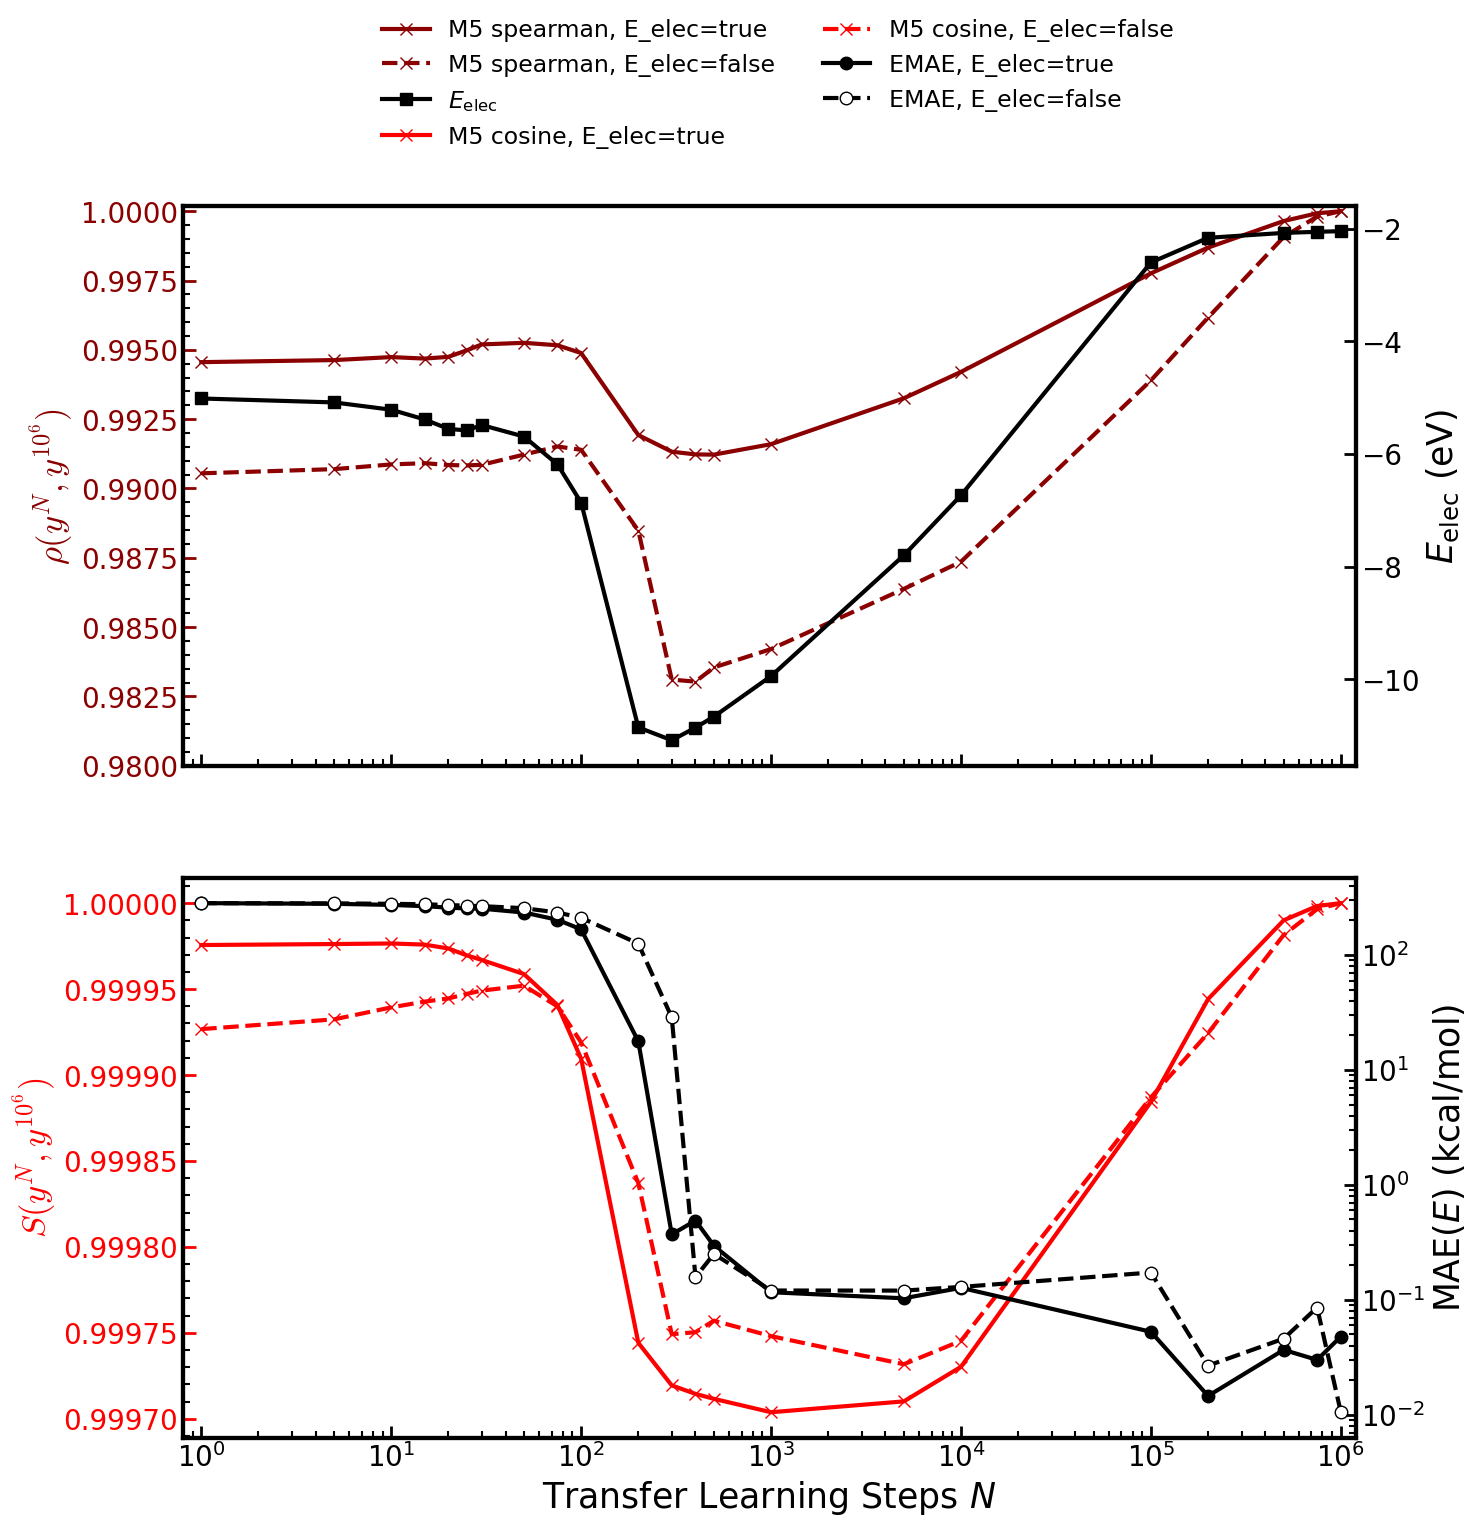

In [17]:
# ============================================================
# FIGURE 2 — TWO ROWS
#
# TOP:    Spearman + Electrostatic Energy
# BOTTOM: Cosine   + Energy MAE
# ============================================================

PLOT_FIGURE_2 = True

SHOW_FIGURE_2 = True
SAVE_FIGURE_2 = True

# ============================================================
# ELECTROSTATIC / MAE CURVES
# ============================================================

SHOW_ELECTROSTATIC_ENERGY_2 = True
SHOW_MAE_2 = True

# Stop if required electrostatic energy data are missing
MISSING_ELEC_2 = "raise"   # "raise" or "omit"

# ============================================================
# MODEL SELECTION
# ============================================================

PLOT_MODE_2 = "both"

# ============================================================
# X AND Y LIMITS
# ============================================================

XLIM_2 = (0.8, 1.2e6)

# Left axes
SPEARMAN_YLIM_2 = (0.98, 1.0002)
COSINE_YLIM_2 = None

# Right axes
ELEC_YLIM_2 = None
MAE_YLIM_2 = None

# ============================================================
# FIGURE SIZE
# ============================================================

FIGSIZE_2 = (17, 16)

# ============================================================
# COLORS
# ============================================================

SPEARMAN_COLOR_2 = "darkred"
COSINE_COLOR_2 = "red"

# ============================================================
# LINE AND MARKERS
# ============================================================

LINE_WIDTH_2 = 3.0
MARKER_SIZE_2 = 9

# ============================================================
# FONTS
# ============================================================

LABEL_SIZE_2 = 25
TICK_SIZE_2 = 20
LEGEND_SIZE_2 = 17

# ============================================================
# AXES / TICKS
# ============================================================

SPINE_WIDTH_2 = 3.0

# ============================================================
# LAYOUT
# ============================================================

LEFT_2 = 0.15
RIGHT_2 = 0.84
BOTTOM_2 = 0.11
TOP_2 = 0.88

HSPACE_2 = 0.20

# ============================================================
# LEGEND
# ============================================================

SHOW_LEGEND_2 = True

LEGEND_NCOL_2 = 2
LEGEND_X_2 = 0.50
LEGEND_Y_2 = 1.01

# ============================================================
# OTHER SETTINGS
# ============================================================

SHOW_GRID_2 = False

DPI_2 = 300

OUTPUT_NAME_2 = "figure2_spearman_eelec_cosine_mae"

# ============================================================
# PLOT FIGURE 2
# ============================================================

if PLOT_FIGURE_2:

    analysis.plot_metrics_with_energy(
        table=df,
        auxiliary=aux,
        reference_checkpoint=REFERENCE_CHECKPOINT,
        mode=PLOT_MODE_2,
        show_plot=SHOW_FIGURE_2,
        save_plot=SAVE_FIGURE_2,
        figsize=FIGSIZE_2,
        xlim=XLIM_2,
        spearman_ylim=SPEARMAN_YLIM_2,
        cosine_ylim=COSINE_YLIM_2,
        elec_ylim=ELEC_YLIM_2,
        mae_ylim=MAE_YLIM_2,
        show_elec=SHOW_ELECTROSTATIC_ENERGY_2,
        show_mae=SHOW_MAE_2,
        missing_elec=MISSING_ELEC_2,
        colors=(
            SPEARMAN_COLOR_2,
            COSINE_COLOR_2,
        ),
        linewidth=LINE_WIDTH_2,
        markersize=MARKER_SIZE_2,
        label_size=LABEL_SIZE_2,
        tick_size=TICK_SIZE_2,
        legend_size=LEGEND_SIZE_2,
        spine_width=SPINE_WIDTH_2,
        left=LEFT_2,
        right=RIGHT_2,
        bottom=BOTTOM_2,
        top=TOP_2,
        hspace=HSPACE_2,
        show_legend=SHOW_LEGEND_2,
        legend_ncol=LEGEND_NCOL_2,
        legend_x=LEGEND_X_2,
        legend_y=LEGEND_Y_2,
        show_grid=SHOW_GRID_2,
        dpi=DPI_2,
        output_name=OUTPUT_NAME_2,
    )

<div style="border: 4px solid navy; border-radius: 8px; padding: 16px 20px; background-color: lightblue; color: black;">

## Cell 10
---

## Atomic Feature Magnitudes and Energy Contributions Along Molecular Dynamics Trajectories

To investigate the relationship between the learned atomic feature representations and the predicted atomic energy contributions, we analyze the evolution of feature-vector magnitudes along a molecular dynamics (MD) trajectory of malonaldehyde at 700 K.

The analysis focuses on a selected trajectory segment containing an intramolecular hydrogen-transfer event. The selected interval consists of 320 molecular configurations, corresponding to trajectory indices 3700–4019, representative of 3700 fs to 4019 fs, along this sets of trajectories a H-trnasfer was observed.

For each atom $\alpha$ and neural-network module $k$, the magnitude of the 128-dimensional atomic feature vector is calculated as

$$
\left\|\mathbf{\mathcal{F}}^\alpha_{k,s}\right\|
=
\sqrt{
\sum_{j=1}^{128}
\left(\mathcal{F}^\alpha_{k,s,j}\right)^2
},
$$

where $s$ denotes the molecular configuration along the trajectory.

The corresponding module-resolved atomic energy contribution, $E^\alpha_{k,s}$, is examined to characterize how variations in the atomic feature-vector magnitude are associated with changes in the predicted atomic energy.

### Computational Implementation

The analysis is implemented using the `MDFeatureEnergy` class defined in `xai_md_feature_energy.py`.

The computational workflow consists of three stages:

1. **Feature extraction:** Atomic feature representations are loaded from `act_hlpes_700K_md_opt_ma_a.xyz.traj.npz`. The initial embedding representation is excluded, retaining the five interaction-module representations (M1–M5). The Euclidean norm of each atomic feature vector is calculated for every selected molecular configuration.

2. **Atomic energy extraction:** Module-resolved atomic energy contributions are obtained from `atomic_energies_700K.npz`, using the `Ea_mod` array. These energies are matched to the corresponding atoms, modules, and molecular configurations. The original energy values are converted from eV to kcal/mol for visualization.

3. **Data organization:** Feature-vector magnitudes and atomic energy contributions are stored as arrays indexed by molecular configuration, module, and atom. The processed numerical data are saved in `~/XAI/data/md_feature_energy/`, avoiding repeated loading of the original large activation files.

The `EXTRACT` variable determines whether the original data are processed again or whether previously extracted quantities are loaded. The `FIRST_FRAME` and `LAST_FRAME` parameters define the trajectory interval using Python indexing, with the final index excluded.

The extracted numerical data are subsequently used to examine the relationship between atomic feature-vector magnitudes and module-resolved atomic energy contributions.

**Implementation:** `~/XAI/xai_md_feature_energy.py`  
**Source data:** `~/XAI/project_feature/md_from_silvan/`  
**Processed data:** `~/XAI/data/md_feature_energy/`  
**MD temperature:** 700 K  
**Selected configurations:** 320 (indices 3700–4019)  
**Neural-network modules:** M1–M5  
**Feature-vector dimensionality:** 128

---

In [18]:

from pathlib import Path
import sys

XAI_ROOT = Path.home() / "XAI"

if str(XAI_ROOT) not in sys.path:
    sys.path.insert(0, str(XAI_ROOT))

%load_ext autoreload
%autoreload 2

from xai_md_feature_energy import MDFeatureEnergy

# ============================================================
# EXTRACTION SETTINGS
# ============================================================

EXTRACT = True

# The default searches both possible copied directory layouts.
SOURCE_DIR = None

ACT_FILE = "act_hlpes_700K_md_opt_ma_a.xyz.traj.npz"
ENERGY_FILE = "atomic_energies_700K.npz"

# Python indexing: start inclusive, end exclusive
FIRST_FRAME = 3700
LAST_FRAME = 4020

# Original Ea_mod energy unit
ENERGY_UNIT = "eV"

# ============================================================
# INITIALIZE
# ============================================================

analysis = MDFeatureEnergy(
    xai_root=XAI_ROOT,
    source_dir=SOURCE_DIR,
)

print("Source directory:", analysis.source)
print("Output directory:", analysis.output)

# ============================================================
# EXTRACT OR LOAD
# ============================================================

if EXTRACT:

    analysis.extract(
        first_frame=FIRST_FRAME,
        last_frame=LAST_FRAME,
        energy_unit=ENERGY_UNIT,
        act_filename=ACT_FILE,
        energy_filename=ENERGY_FILE,
    )

data = analysis.load()

print("\nStaged data shapes:")
for key, value in data.items():
    print(f"  {key}: {value.shape}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Source directory: /mmhome/chaton/XAI/project_feature/md_from_silvan/activations
Output directory: /mmhome/chaton/XAI/data/md_feature_energy
Source: /mmhome/chaton/XAI/project_feature/md_from_silvan/activations
Loading activation array (source NPZ may be ~1.1 GB)...
Loading atomic energy array...
Staged: /mmhome/chaton/XAI/data/md_feature_energy/feature_energy_700K_frames_3700_4019.npz | arrays: (320, 5, 9) (320, 5, 9)

Staged data shapes:
  frames: (320,)
  magnitude: (320, 5, 9)
  energy_kcalmol: (320, 5, 9)


<div style="border: 4px solid navy; border-radius: 8px; padding: 16px 20px; background-color: lightblue; color: black;">

## Cell 11

---

## Correlation Between Atomic Feature Magnitude and Module-Resolved Atomic Energy

Using the extracted atomic feature magnitudes and module-resolved atomic energy contributions, we now examine their relationship for selected atoms along the 700 K molecular dynamics trajectory.

The figure is arranged as a **5 × 3 panel plot**:

- **Rows:** PhysNet modules M1–M5  
- **Columns:** atoms C1, O7, and H8

For each selected atom $\alpha$ and module $k$, the horizontal axis shows the magnitude of the atomic feature vector,

$$
\left\|\mathbf{\mathcal{F}}^\alpha_{k,s}\right\|,
$$

while the vertical axis shows the corresponding module-resolved atomic energy contribution,

$$
E^\alpha_{k,s}.
$$

Each point represents one molecular configuration $s$ from the selected MD segment. The initial and final configurations of the trajectory window are highlighted separately to indicate the beginning and end of the sampled structural evolution.

### Physical Interpretation

This analysis is used to examine whether variations in the scale of the learned atomic representation are associated with systematic changes in the predicted atomic energy contribution. Because the figure is resolved by both atom and neural-network module, it allows one to identify:

- whether the feature–energy relationship differs between atoms,
- how this relationship changes across the five PhysNet modules,

The selected atoms C1, O7, and H8 are of particular interest because they are directly involved in the structural and electronic reorganization associated with intramolecular hydrogen transfer.

### Computational Implementation

The plotting is performed using the `plot()` method of the `MDFeatureEnergy` class.

1. **Panel selection:** The `MODULES` variable determines which PhysNet modules are included, while `ATOMS` specifies the selected atoms and their display labels.

2. **Scatter visualization:** For each module–atom pair, the staged feature magnitudes and module-resolved atomic energies are plotted as scatter points. The first and last geometries of the selected trajectory interval are highlighted separately.

3. **Panel-specific formatting:** Axis labels, font sizes, subplot spacing, axis thickness, tick parameters, and optional panel-specific axis limits are controlled directly in the Jupyter cell.

4. **Output:** The resulting figure is saved in `~/XAI/data/md_feature_energy/` in both raster and vector formats, allowing later reuse in analysis or manuscript preparation.

The `XLIMS` and `YLIMS` dictionaries provide optional manual axis control for individual panels using keys of the form `(module_number, atom_number)`. If these dictionaries are empty, limits are determined automatically from the plotted data.

**Plotting method:** `MDFeatureEnergy.plot()`  
**Figure layout:** 5 rows × 3 columns  
**Selected atoms:** C1, O7, H8  
**Neural-network modules:** M1–M5  
**Trajectory segment:** frames 3700–4019  
**Output directory:** `~/XAI/data/md_feature_energy/`

---

/mmhome/chaton/XAI/xai_md_feature_energy.py:138: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.grid(show_grid,alpha=.25)


Saved: /mmhome/chaton/XAI/data/md_feature_energy/feature_magnitude_vs_atomic_energy_5x3.png
Saved: /mmhome/chaton/XAI/data/md_feature_energy/feature_magnitude_vs_atomic_energy_5x3.pdf


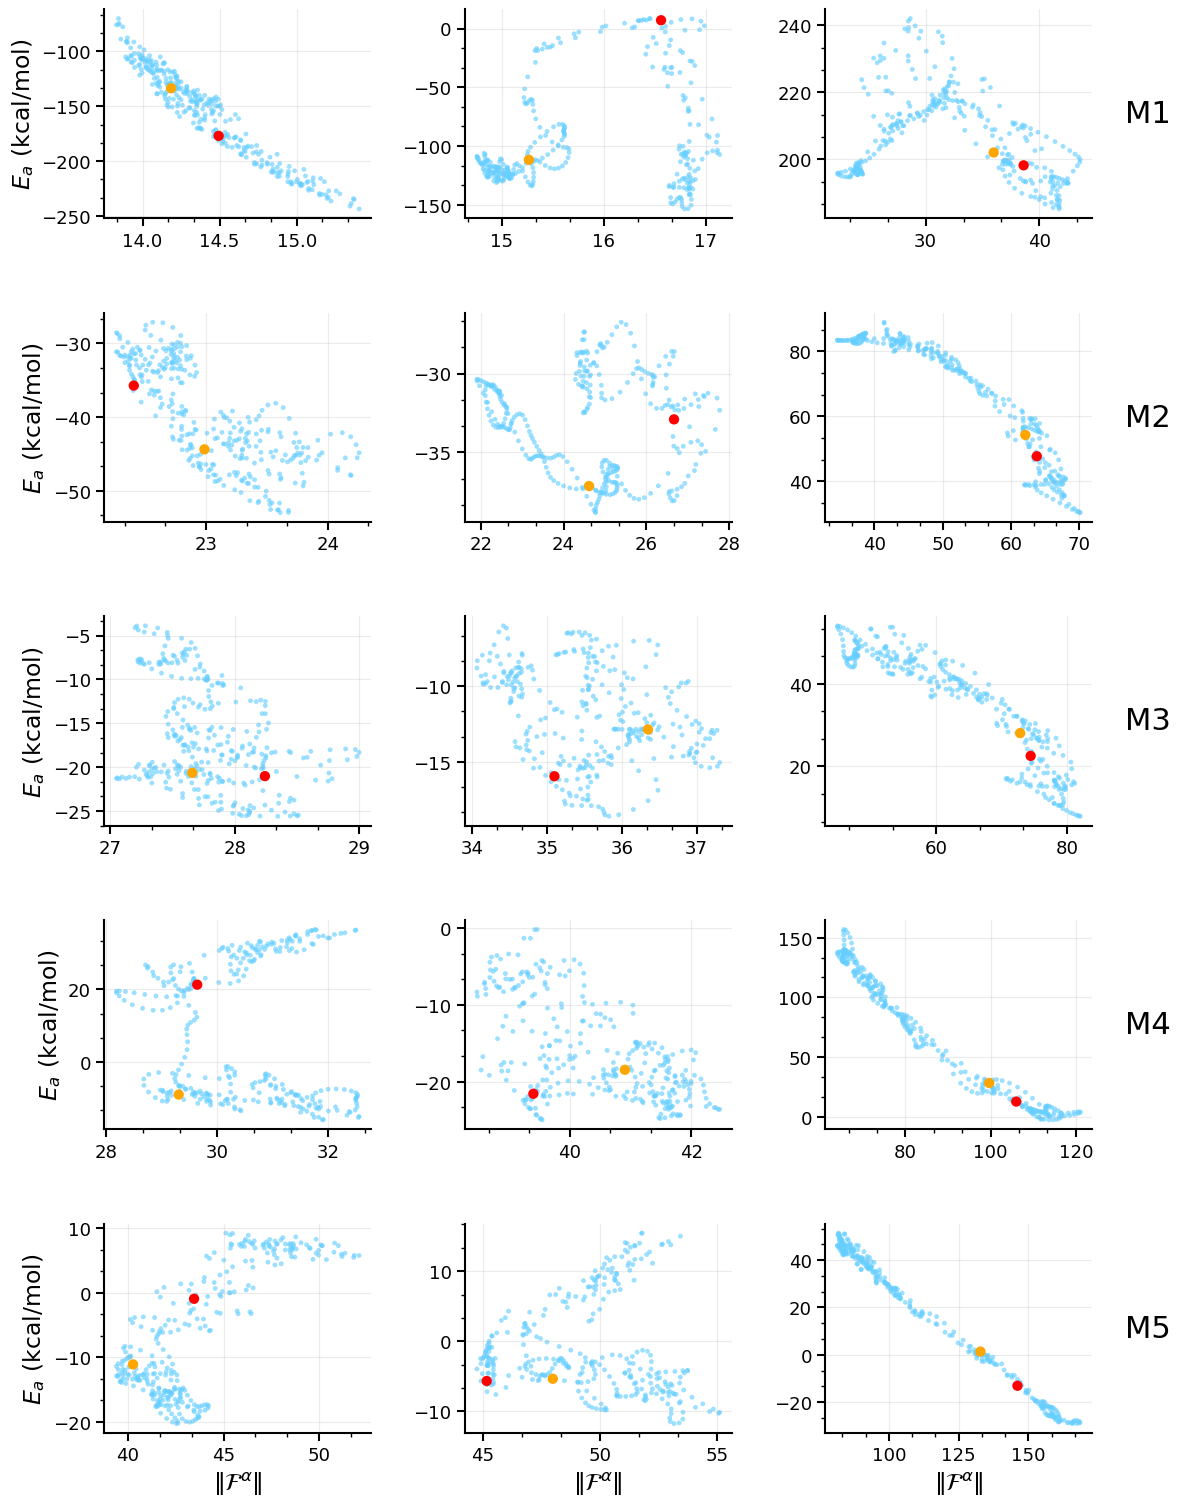

In [19]:

# ============================================================
# FIGURE — FEATURE MAGNITUDE VS ATOMIC ENERGY
#
# Rows    : M1, M2, M3, M4, M5
# Columns : C1, O7, H8
# ============================================================

PLOT_FIGURE = True
SHOW_PLOT = True
SAVE_PLOT = True

OUTPUT_NAME = "feature_magnitude_vs_atomic_energy_5x3"

# ============================================================
# MODULE AND ATOM SELECTION
# ============================================================

MODULES = (1, 2, 3, 4, 5)

# Atom numbers are 1-based
ATOMS = (
    (1, "C1"),
    (7, "O7"),
    (8, "H8"),
)

# ============================================================
# FIGURE SIZE
# ============================================================

FIGSIZE = (13, 16)
DPI = 300

# ============================================================
# SCATTER SETTINGS
# ============================================================

POINT_COLOR = "#67cfff"
POINT_SIZE = 12
POINT_ALPHA = 0.65

# First and last geometry
START_COLOR = "orange"
END_COLOR = "red"
ENDPOINT_SIZE = 55

# ============================================================
# AXIS LABELS
# ============================================================

XLABEL = r"$\|\mathcal{F}^{\alpha}\|$"
YLABEL = r"$E_a$ (kcal/mol)"

# ============================================================
# FONT SIZES
# ============================================================

LABEL_SIZE = 17
TICK_SIZE = 13
MODULE_LABEL_SIZE = 22
COLUMN_LABEL_SIZE = 17

# ============================================================
# AXIS THICKNESS
# ============================================================

SPINE_WIDTH = 1.5

# ============================================================
# MAJOR / MINOR TICKS
# ============================================================

MAJOR_TICK_LENGTH = 6
MAJOR_TICK_WIDTH = 1.5

MINOR_TICK_LENGTH = 3
MINOR_TICK_WIDTH = 1.0

MINOR_SUBDIVISIONS = 3

# ============================================================
# MANUAL AXIS LIMITS
#
# Keys: (module_number, atom_number)
#
# Empty dictionaries = automatic limits for every panel.
# ============================================================

XLIMS = {
    # (1, 1): (15, 19),
    # (1, 7): (14, 18),
    # (5, 8): (80, 180),
}

YLIMS = {
    # (1, 1): (-310, -180),
    # (1, 7): (-160, 20),
    # (5, 8): (-30, 55),
}

# ============================================================
# FIGURE MARGINS
# ============================================================

LEFT = 0.12
RIGHT = 0.88
BOTTOM = 0.08
TOP = 0.97

WSPACE = 0.35
HSPACE = 0.45

# ============================================================
# DISPLAY SETTINGS
# ============================================================

SHOW_GRID = False
SHOW_COLUMN_TITLES = False

# ============================================================
# PLOT
# ============================================================

if PLOT_FIGURE:

    analysis.plot(
        data=data,
        modules=MODULES,
        atoms=ATOMS,
        figsize=FIGSIZE,
        dpi=DPI,

        point_color=POINT_COLOR,
        point_size=POINT_SIZE,
        point_alpha=POINT_ALPHA,

        start_color=START_COLOR,
        end_color=END_COLOR,
        endpoint_size=ENDPOINT_SIZE,

        xlabel=XLABEL,
        ylabel=YLABEL,

        label_size=LABEL_SIZE,
        tick_size=TICK_SIZE,
        module_label_size=MODULE_LABEL_SIZE,
        column_label_size=COLUMN_LABEL_SIZE,

        spine_width=SPINE_WIDTH,

        major_tick_length=MAJOR_TICK_LENGTH,
        major_tick_width=MAJOR_TICK_WIDTH,
        minor_tick_length=MINOR_TICK_LENGTH,
        minor_tick_width=MINOR_TICK_WIDTH,
        minor_subdivisions=MINOR_SUBDIVISIONS,

        left=LEFT,
        right=RIGHT,
        bottom=BOTTOM,
        top=TOP,
        wspace=WSPACE,
        hspace=HSPACE,

        xlims=XLIMS,
        ylims=YLIMS,

        show_grid=SHOW_GRID,
        show_column_titles=SHOW_COLUMN_TITLES,

        show=SHOW_PLOT,
        save=SAVE_PLOT,
        output_name=OUTPUT_NAME,
    )
